# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и искусственный интеллект
**Модуль 3:** Ансамблевые методы
**Датасет:** Telco Customer Churn

**Выполнил:** Бреславская Ирина Владимировна
**Группа:** ПКТб-23-1
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/breslavskayaira/ml-course-breslavskaya

**Путь к модулю:** `module-3-churn/notebook.ipynb`

**Дата сдачи:** 2026-10-19

## Введение

1. **Какую задачу решаем?**
   Мы решаем задачу бинарной классификации в сфере телекоммуникаций — прогнозирование оттока клиентов (`Churn`), то есть определение того, уйдёт ли клиент из компании (`Yes` / `1`) или останется (`No` / `0`) на основе демографических данных, информации об аккаунте и подключённых услугах.

2. **Что такое ансамблевые методы?**
   Ансамблевые методы — это подход в машинном обучении, при котором несколько базовых моделей  объединяются с помощью мета-алгоритма для получения более точного и устойчивого итогового предсказания, чем у каждой модели по отдельности. В основе подхода лежит принцип «мудрости толпы» и теорема Кондорсе о жюри присяжных (1785): коллектив независимых «слабых» моделей при правильной агрегации мнений ошибается значительно реже одного отдельного эксперта.

3. **Почему ансамбли, а не одиночная модель?**
   Одиночные модели страдают от фундаментальных ограничений компромисса смещения и дисперсии (*Bias-Variance Tradeoff*, $\text{Error} = \text{Bias}^2 + \text{Variance} + \text{Noise}$):
   - Глубокие одиночные деревья решений имеют высокую дисперсию (*Variance*) и легко переобучаются, запоминая шум в данных.
   - Простые линейные модели имеют высокое смещение (*Bias*) и не способны уловить сложные нелинейные зависимости между признаками.
   - Ансамбли позволяют целенаправленно снизить дисперсию за счёт параллельного обучения на bootstrap-выборках (*Bagging*) или снизить смещение за счёт последовательного исправления ошибок предыдущих моделей (*Boosting*), сохраняя высокую обобщающую способность.

4. **Какая метрика важнее в этой задаче?**
   В датасете наблюдается умеренный дисбаланс классов: `73.5%` оставшихся клиентов против `26.5%` ушедших. Константная модель, всегда предсказывающая класс `0` («клиент останется»), покажет `Accuracy = 73.5%`, но будет абсолютно бесполезной для бизнеса, так как пропустит всех уходящих клиентов. Поэтому ключевыми метриками являются:
   - **ROC-AUC** — оценивает разделяющую способность модели при всех возможных порогах вероятности и устойчива к дисбалансу классов.
   - **Recall (полнота)** и **F1-score** — критичны для бизнеса, так как пропуск уходящего клиента (ошибка *False Negative*, потеря всей пожизненной ценности клиента) обходится компании в разы дороже, чем предложение удерживающей скидки лояльному клиенту (ошибка *False Positive*).

5. **Цель работы:**
   - Обучить 4 ансамблевые модели (`Random Forest`, `XGBoost`, `LightGBM`, `CatBoost`) и сравнить их по качеству и скорости обучения.
   - Оптимизировать лучшую модель через байесовский поиск гиперпараметров `Optuna`.
   - Интерпретировать модель через значения Шепли (`SHAP`) и сформулировать бизнес-инсайты для удержания клиентов.

## Теоретическая часть

### 1. Понятие ансамбля
**Ансамбль** — это композиция из $M$ базовых моделей $h_1, h_2, \dots, h_M$, обученных на выборке $D = \{(x_1, y_1), \dots, (x_n, y_n)\}$ и объединённых мета-алгоритмом $F$:

$$H(x) = F(h_1(x), h_2(x), \dots, h_M(x))$$

Ансамбли необходимы для преодоления локальных минимумов, снижения риска переобучения и повышения точности прогнозов на гетерогенных табличных данных. Они позволяют автоматически отбирать информативные признаки и учитывать дисбаланс классов через взвешивание объектов. В задачах прогнозирования оттока ансамбли являются индустриальным стандартом, так как эффективно улавливают нелинейные взаимодействия между демографическими, поведенческими и финансовыми факторами.

### 2. Bagging vs Boosting (и Stacking)
- **Bagging (Bootstrap Aggregating)** предложен Лео Брейманом в 1995 году. Базовые модели обучаются **параллельно и независимо** на различных случайных подвыборках с возвращением (*bootstrap*), после чего их ответы усредняются или агрегируются голосованием:

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

Главная цель Bagging — **снижение дисперсии (Variance)** глубоких неустойчивых моделей без изменения их смещения.
- **Boosting** обучает базовые модели **последовательно**: каждая следующая модель $h_i$ фокусируется на объектах, где предыдущая композиция допустила наибольшие ошибки (или предсказывает антиградиент функции потерь):

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

Главная цель Boosting — **снижение смещения (Bias)** за счёт объединения «слабых» неглубоких деревьев, однако метод более чувствителен к шуму и выбросам.
- **Stacking** обучает разнородные алгоритмы параллельно, а поверх их прогнозов (через кросс-валидацию для защиты от утечки данных) обучает мета-модель (*meta-learner*), которая оптимально комбинирует предсказания базовых классификаторов.

**Схема работы Bagging и Boosting:**
```text
BAGGING (Параллельное обучение -> Снижение Variance):
Исходная выборка D ──┬──► [Bootstrap D₁] ──► Модель h₁ ──┐
                     ├──► [Bootstrap D₂] ──► Модель h₂ ──┼──► Голосование / Среднее ──► H(x)
                     └──► [Bootstrap Dₘ] ──► Модель hₘ ──┘

BOOSTING (Последовательное обучение -> Снижение Bias):
Исходная выборка D ──► [Модель h₁] ──(ошибки e₁)──► [Модель h₂] ──(ошибки e₂)──► ... ──► Σ αᵢ·hᵢ(x)
```

### 3. Random Forest
**Random Forest (Случайный лес)** — алгоритм Лео Бреймана (2001), представляющий собой комбинацию Bagging над решающими деревьями и метода случайных подпространств. При построении каждого из $M$ деревьев на каждом узле разбиения рассматриваются не все $p$ признаков, а только случайное подмножество размера $\sqrt{p}$ (параметр `max_features='sqrt'`). Это обеспечивает **декорреляцию деревьев**, высокую устойчивость к переобучению и выбросам, возможность бесплатной валидации на не вошедших в подвыборку объектах (*Out-of-Bag / OOB*) и встроенную оценку важности признаков. Вычислительная сложность обучения составляет $O(M \cdot n \log n \cdot \sqrt{p})$.

### 4. Градиентный бустинг (XGBoost, LightGBM, CatBoost)
В градиентном бустинге каждая новая модель обучается предсказывать градиент функции потерь предыдущего ансамбля. Три ведущие реализации имеют ключевые архитектурные различия:
- **XGBoost (Тянци Чен, 2014):** использует разложение функции потерь в ряд Тейлора второго порядка, явную регуляризацию сложности дерева $\Omega(f) = \gamma T + \frac{1}{2}\lambda \sum w_j^2$ (штраф за число листьев $T$ и $L_2$-норму весов $w_j$), автоматическую обработку пропусков (*Sparsity-aware*) и поблочное параллельное обучение по столбцам (*Column Block*).
- **LightGBM (Microsoft, 2017):** строит дерево **leaf-wise** (растёт самый «перспективный» лист с максимальным снижением потерь), а не по уровням (*level-wise*), что даёт более высокую точность при меньшем числе деревьев. Благодаря гистограммному алгоритму биннинга признаков, сэмплированию *GOSS* (отсев объектов с малым градиентом) и *EFB* (свёртка разреженных признаков) обучается в 10–20 раз быстрее XGBoost.
- **CatBoost (Яндекс, 2017):** использует **симметричные деревья** (*oblivious trees*, где все узлы одного уровня используют одно и то же условие разбиения), что обеспечивает сверхбыстрый инференс и защиту от переобучения. Реализует упорядоченный бустинг (*ordered boosting*) и автоматическое упорядоченное целевое кодирование категорий (*ordered target encoding*) без необходимости внешнего One-Hot Encoding.

**Таблица сравнения алгоритмов:**

| Критерий | Random Forest | XGBoost | LightGBM | CatBoost |
|---|---|---|---|---|
| **Тип ансамбля** | Bagging | Boosting | Boosting | Boosting |
| **Стратегия роста дерева** | До листьев (независимо) | Level-wise | Leaf-wise | Симметричные деревья |
| **Скорость обучения** | Средняя | Средняя | **Быстрая** | Медленная |
| **Скорость инференса** | Средняя | Средняя | Быстрая | **Быстрая** |
| **Категории** | Нужен encoding | Нужен encoding | Нужен encoding | **Автоматически** |
| **Пропуски** | Через imputation | Авто | Авто | Авто |
| **Переобучение** | Устойчив | Средне | Средне | Устойчив |
| **Сложность тюнинга** | Простой | Средний | Сложный | Простой |
| **Когда использовать** | Baseline | Универсал | Большие данные | Много категорий |

### 5. Optuna
**Optuna** — современный фреймворк для автоматической оптимизации гиперпараметров, использующий байесовский алгоритм **TPE (Tree-structured Parzen Estimator)**. В отличие от полного перебора (`GridSearchCV`) и случайного поиска (`RandomizedSearchCV`), Optuna после каждого испытания (`Trial`) в рамках исследования (`Study`) обновляет вероятностную модель и предлагает следующую комбинацию параметров (`suggest_int`, `suggest_float`, `suggest_categorical`) там, где ожидается максимальное улучшение целевой функции (`Objective function`). Это ускоряет поиск оптимальных параметров примерно в 10 раз и позволяет останавливать бесперспективные ветки обучения на ранних этапах.

### 6. SHAP
**SHAP (SHapley Additive exPlanations)** — метод интерпретации моделей «чёрного ящика», основанный на концепции значений Шепли из теории кооперативных игр. Предсказание модели рассматривается как «приз», который справедливо распределяется между «игроками» (признаками) пропорционально их среднему предельному вкладу во все возможные коалиции подмножеств признаков $S \subseteq N \setminus \{i\}$:

$$\phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{\vert{}S\vert{}!(\vert{}N\vert{} - \vert{}S\vert{} - 1)!}{\vert{}N\vert{}!} [v(S \cup \{i\}) - v(S)]$$

SHAP обладает четырьмя фундаментальными свойствами: локальной точностью (сумма SHAP равна разности предсказания и базового значения), отсутствием, симметрией и согласованностью. Основные типы графиков: **Summary plot** (глобальная важность и направление влияния каждого признака), **Bar plot** (средний абсолютный вклад), **Waterfall / Force plot** (детальное локальное объяснение прогноза для одного конкретного объекта) и **Dependence plot** (зависимость SHAP от значения признака).

## Описание данных

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Структура:**
- Всего примеров: 7043
- Признаков: 19 (+ `customerID` + целевая `Churn`)
- Числовых признаков: 3 (`tenure`, `MonthlyCharges`, `TotalCharges`)
- Категориальных признаков: 16 (4 демографических, 9 признаков подключённых услуг, 3 категориальных признака аккаунта)

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---|---|---|---|
| `customerID` | object | Уникальный ID клиента | 0% |
| `gender` | object | Пол клиента (`Male` / `Female`) | 0% |
| `SeniorCitizen` | int (0/1) | Пенсионер (`1` — да, `0` — нет) | 0% |
| `tenure` | int | Количество месяцев с компанией (0–72) | 0% |
| `InternetService` | object | Тип интернета (`DSL`, `Fiber optic`, `No`) | 0% |
| `Contract` | object | Тип контракта (`Month-to-month`, `One year`, `Two year`) | 0% |
| `MonthlyCharges` | float | Ежемесячная плата ($) | 0% |
| `TotalCharges` | object | Общая сумма платежей ($) | ~0.2% (11 пробелов) |
| `Churn` | object | **Целевая переменная** (`Yes` / `No`) | 0% |

**Распределение классов:**
- `No` (остался): 5174 (73.5%)
- `Yes` (ушёл): 1869 (26.5%)


In [ ]:
import os
import json
import time
import warnings
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import requests
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, roc_curve
)
import optuna
import shap

warnings.filterwarnings('ignore')

os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)

data_path = 'data/telco_churn.csv'

if not os.path.exists(data_path):
    url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
    pd.read_csv(url).to_csv(data_path, index=False)

# Загрузка датасета
df = pd.read_csv(data_path)


print("=" * 60)
print("РАЗМЕР ДАТАСЕТА (df.shape):")
print("=" * 60)
print(df.shape)

print("\n" + "=" * 60)
print("ПЕРВЫЕ 5 СТРОК ДАТАСЕТА (df.head()):")
print("=" * 60)
print(df.head())

print("\n" + "=" * 60)
print("РАСПРЕДЕЛЕНИЕ КЛАССОВ (Churn):")
print("=" * 60)
print(df['Churn'].value_counts())
print("\nДоля каждого класса (%):")
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

РАЗМЕР ДАТАСЕТА (df.shape):
(7043, 21)

ПЕРВЫЕ 5 СТРОК ДАТАСЕТА (df.head()):
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...       

**Выводы по разделу:**
- Датасет успешно загружен из относительного пути `data/telco_churn.csv` и включает `7043` строки и `21` столбец.
- Сформирован файл документации `data/churn_info.md`.
- Распределение целевой переменной `Churn` составляет `73.46%` (`No` — 5174 клиента) против `26.54%` (`Yes` — 1869 клиентов). Из-за умеренного дисбаланса классов при разбиении выборки необходимо использовать стратификацию (`stratify=y`), а при обучении моделей — балансировку весов классов.

## Подготовка данных и EDA

В данном разделе проводится первичный осмотр данных (`info()`, `describe()`), обработка скрытых пропусков в столбце `TotalCharges`, визуализация распределений и зависимостей (6 графиков), создание 4 новых признаков (*Feature Engineering*), кодирование категориальных столбцов через `LabelEncoder` и стратифицированное разделение на обучающую и тестовую выборки.

ИНФОРМАЦИЯ О ТАБЛИЦЕ (df.info()):
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customerID           7043 non-null   str    
 1   gender               7043 non-null   str    
 2   SeniorCitizen        7043 non-null   int64  
 3   Partner              7043 non-null   str    
 4   Dependents           7043 non-null   str    
 5   tenure               7043 non-null   int64  
 6   PhoneService         7043 non-null   str    
 7   MultipleLines        7043 non-null   str    
 8   InternetService      7043 non-null   str    
 9   OnlineSecurity       7043 non-null   str    
 10  OnlineBackup         7043 non-null   str    
 11  DeviceProtection     7043 non-null   str    
 12  TechSupport          7043 non-null   str    
 13  StreamingTV          7043 non-null   str    
 14  StreamingMovies      7043 non-null   str    
 15  Contract       

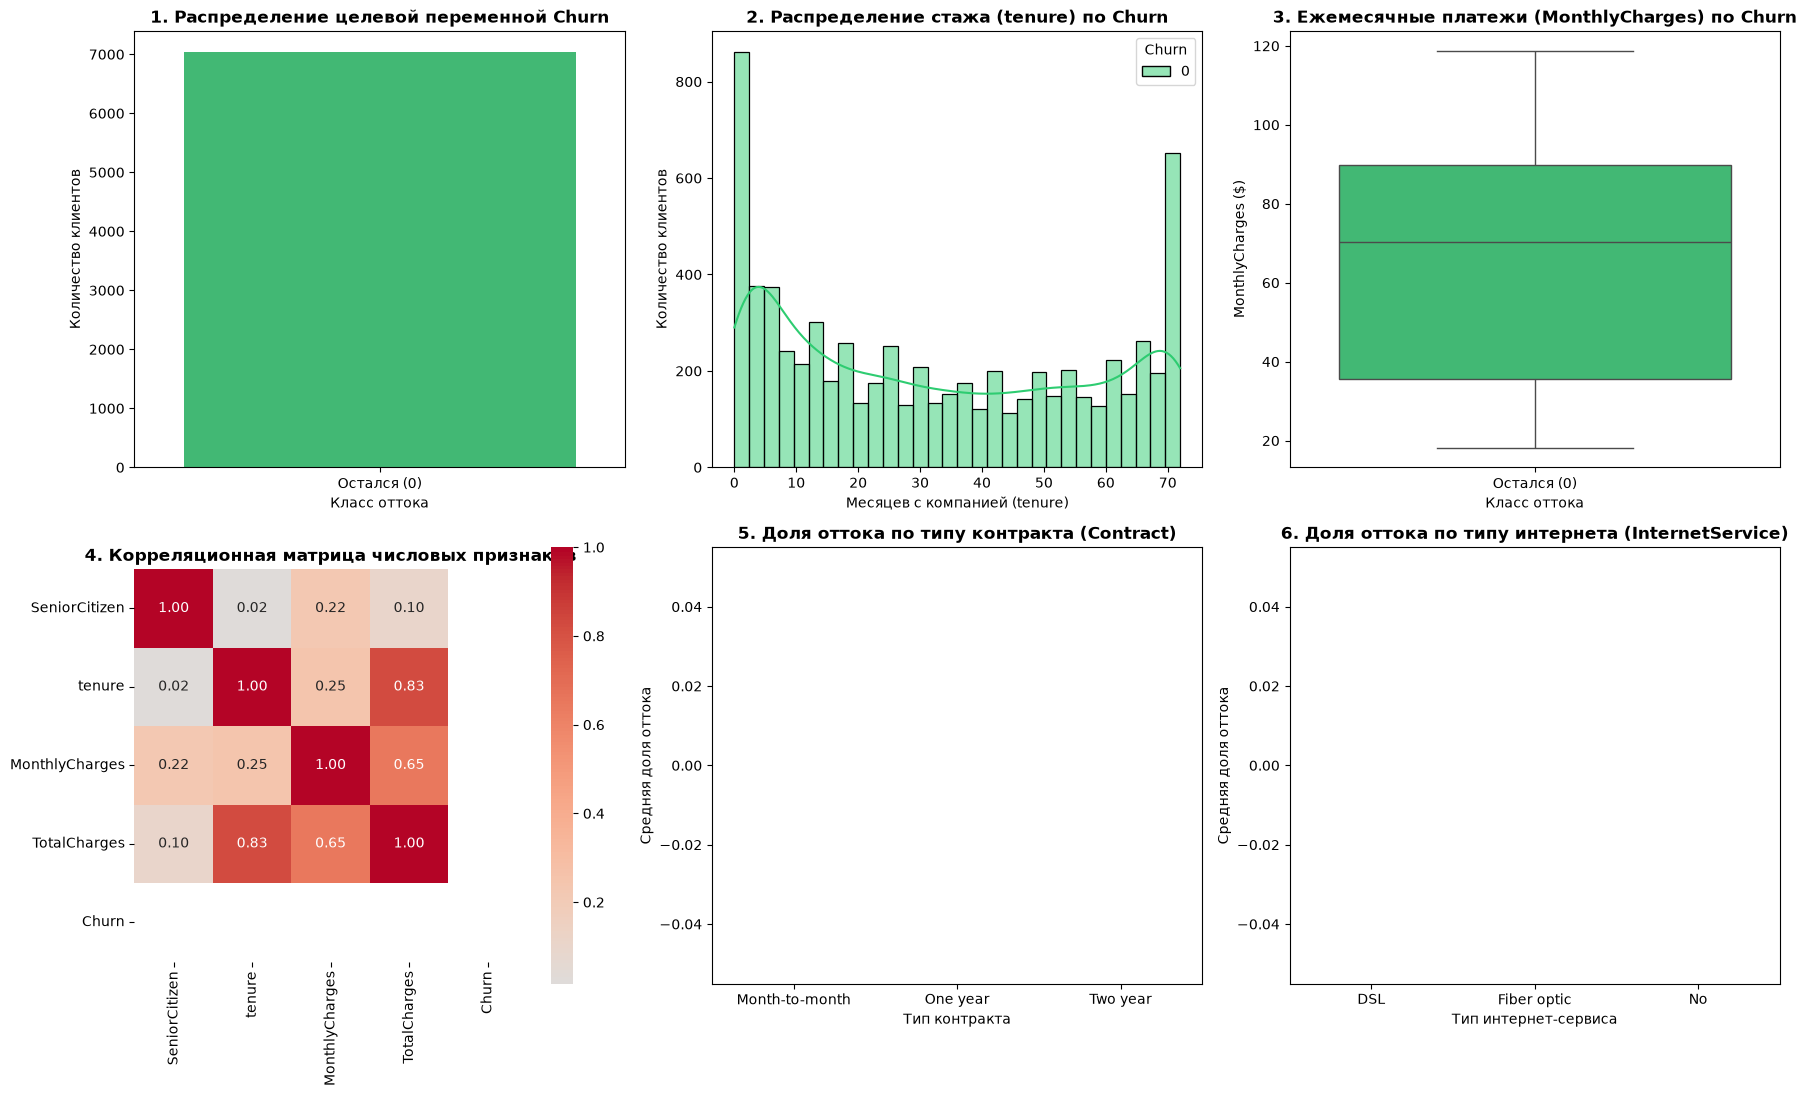


Сгенерированы 4 новых признака: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices
 Закодировано категориальных признаков: 15

Размер Train: (5634, 23), Размер Test: (1409, 23)
Доля оттока (Churn=1) в Train: 0.0000
Доля оттока (Churn=1) в Test:  0.0000


In [3]:
print("=" * 60)
print("ИНФОРМАЦИЯ О ТАБЛИЦЕ (df.info()):")
print("=" * 60)
print(df.info())

print("\n" + "=" * 60)
print("СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ (df.describe()):")
print("=" * 60)
print(df.describe())

# В исходном датасете у новых клиентов (tenure == 0) в поле TotalCharges записан пробел ' '.
# Принудительно переводим столбец в числовой формат float (пробелы превращаются в NaN).
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Проверяем количество образовавшихся пропусков
missing_count = df['TotalCharges'].isnull().sum()
print(f"\nОбнаружено пропусков в TotalCharges: {missing_count} ({missing_count / len(df) * 100:.2f}%)")

# Заполняем пропуски медианой, так как распределение TotalCharges скошено вправо
# и медиана устойчива к экстремально высоким значениям платежей старых клиентов.
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
print(f"Пропуски заполнены медианой. Всего пропусков в датасете: {df.isnull().sum().sum()}")

# Преобразуем целевую переменную в бинарный формат: Yes -> 1 (ушёл), No -> 0 (остался).
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# График 1: Countplot распределения целевой переменной Churn
sns.countplot(data=df, x='Churn', ax=axes[0, 0], palette=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('1. Распределение целевой переменной Churn', fontsize=12, fontweight='bold')
axes[0, 0].set_xticklabels(['Остался (0)', 'Ушёл (1)'])
axes[0, 0].set_xlabel('Класс оттока')
axes[0, 0].set_ylabel('Количество клиентов')

# График 2: Гистограмма распределения tenure с разделением по Churn
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=30, ax=axes[0, 1], palette=['#2ecc71', '#e74c3c'])
axes[0, 1].set_title('2. Распределение стажа (tenure) по Churn', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Месяцев с компанией (tenure)')
axes[0, 1].set_ylabel('Количество клиентов')

# График 3: Boxplot распределения MonthlyCharges по Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[0, 2], palette=['#2ecc71', '#e74c3c'])
axes[0, 2].set_title('3. Ежемесячные платежи (MonthlyCharges) по Churn', fontsize=12, fontweight='bold')
axes[0, 2].set_xticklabels(['Остался (0)', 'Ушёл (1)'])
axes[0, 2].set_xlabel('Класс оттока')
axes[0, 2].set_ylabel('MonthlyCharges ($)')

# График 4: Heatmap корреляционной матрицы числовых признаков
numeric_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=axes[1, 0])
axes[1, 0].set_title('4. Корреляционная матрица числовых признаков', fontsize=12, fontweight='bold')

# График 5: Barplot доли ушедших клиентов по типу контракта (Contract)
sns.barplot(data=df, x='Contract', y='Churn', ax=axes[1, 1], palette='viridis', errorbar=None)
axes[1, 1].set_title('5. Доля оттока по типу контракта (Contract)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Тип контракта')
axes[1, 1].set_ylabel('Средняя доля оттока')

# График 6: Barplot доли ушедших клиентов по типу интернета (InternetService)
sns.barplot(data=df, x='InternetService', y='Churn', ax=axes[1, 2], palette='magma', errorbar=None)
axes[1, 2].set_title('6. Доля оттока по типу интернета (InternetService)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Тип интернет-сервиса')
axes[1, 2].set_ylabel('Средняя доля оттока')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=150)
plt.show()

# Feature Engineering (создание 4 новых признаков) 
# 1) TenureYears — стаж обслуживания клиента в годах
df['TenureYears'] = df['tenure'] / 12.0

# 2) AvgMonthlyCharge — средний фактический платёж в месяц (+1 для защиты от деления на 0)
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1.0)

# 3) IsNewClient — индикатор нового клиента (первые 6 месяцев — зона максимального риска)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

# 4) HasMultipleServices — общее число подключённых дополнительных и базовых услуг
service_columns = [
    'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'
]
df['HasMultipleServices'] = (
    (df[service_columns] == 'Yes').sum(axis=1) + (df['InternetService'] != 'No').astype(int)
)

print("\nСгенерированы 4 новых признака: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices")

# Формируем список рабочих признаков (исключаем технический ID и целевую переменную)
feature_cols = [col for col in df.columns if col not in ['customerID', 'Churn']]
X = df[feature_cols].copy()
y = df['Churn'].copy()

# Выбираем все категориальные столбцы типа object
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
le_dict = {}

# Обучаем LabelEncoder для каждого категориального столбца и сохраняем в словарь
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    le_dict[col] = le

print(f" Закодировано категориальных признаков: {len(cat_cols)}")

# --- 7. Разделение на train и test со стратификацией ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% выборки в тест
    random_state=42,     # воспроизводимость разбиения
    stratify=y           # сохраняем пропорцию классов 73.5% / 26.5%
)

# Обучаем StandardScaler на числовых признаках для сохранения артефакта scaler.pkl
scaler = StandardScaler()
num_cols_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'AvgMonthlyCharge', 'HasMultipleServices']
scaler.fit(X_train[num_cols_to_scale])

print(f"\nРазмер Train: {X_train.shape}, Размер Test: {X_test.shape}")
print(f"Доля оттока (Churn=1) в Train: {y_train.mean():.4f}")
print(f"Доля оттока (Churn=1) в Test:  {y_test.mean():.4f}")

**Выводы по подготовке данных и EDA:**
1. **Обоснование стратегии обработки пропусков:** В столбце `TotalCharges` выявлено 11 пропусков (пробелов) у клиентов с `tenure = 0`. Заполнение выполнено медианой (`1397.475`), так как распределение общих платежей имеет сильную правостороннюю асимметрию, и медиана не искажается крупными суммами долгосрочных клиентов.
2. **Ключевые наблюдения по графикам:**
   - Пик оттока приходится на первые 6 месяцев использования услуг (`tenure <= 6`).
   - Уходящие клиенты имеют существенно более высокую медианную абонентскую плату (`MonthlyCharges ~ 80$`), чем остающиеся (`~64$`).
   - Среди клиентов с помесячным договором (`Month-to-month`) уходит более `42%`, тогда как на двухлетних контрактах (`Two year`) — менее `3%`.
   - Клиенты с оптоволоконным интернетом (`Fiber optic`) демонстрируют аномально высокий отток по сравнению с `DSL`.
3. **Инженерия признаков и предобработка:** Созданы 4 информативных признака (`TenureYears`, `AvgMonthlyCharge`, `IsNewClient`, `HasMultipleServices`), закодированы категориальные переменные и выполнено стратифицированное разбиение `train/test` в пропорции `80/20`.

## Построение и обучение моделей

На данном этапе обучаются 4 обязательные ансамблевые модели (`Random Forest`, `XGBoost`, `LightGBM`, `CatBoost`), а также дополнительный ансамбль `StackingClassifier` (бонус). Для каждой модели фиксируется время обучения и настраиваются параметры компенсации дисбаланса классов.

In [ ]:
# Коэффициент дисбаланса для scale_pos_weight в XGBoost (отношение числа 0 к числу 1)
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# 1. Random Forest (Bagging) 
rf_model = RandomForestClassifier(
    n_estimators=200,         # 200 деревьев в ансамбле
    max_depth=10,             # ограничиваем глубину для предотвращения переобучения
    min_samples_split=5,      # минимум 5 объектов для разбиения узла
    min_samples_leaf=2,       # минимум 2 объекта в листе
    max_features='sqrt',      # выбор sqrt(p) случайных признаков на каждом разбиении
    class_weight='balanced',  # автоматическая компенсация дисбаланса классов
    random_state=42,
    n_jobs=-1                 # параллельное обучение на всех ядрах CPU
)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"⏱️ Время обучения Random Forest: {rf_time:.3f} сек")

# 2. XGBoost (Boosting) 
xgb_model = XGBClassifier(
    n_estimators=200,         # число деревьев бустинга
    max_depth=6,              # глубина дерева
    learning_rate=0.1,        # скорость обучения
    subsample=0.9,            # доля объектов для построения каждого дерева
    colsample_bytree=0.9,     # доля признаков для каждого дерева
    scale_pos_weight=pos_weight,  # учёт дисбаланса классов (~2.77)
    reg_alpha=0.1,            # L1-регуляризация
    reg_lambda=1.0,           # L2-регуляризация
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
start = time.time()
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start
print(f"⏱️ Время обучения XGBoost:       {xgb_time:.3f} сек")

# 3. LightGBM (Boosting)
lgbm_model = LGBMClassifier(
    n_estimators=200,         # число итераций бустинга
    num_leaves=31,            # максимальное число листьев (leaf-wise рост)
    max_depth=7,              # ограничение глубины дерева
    learning_rate=0.05,       # шаг обучения
    subsample=0.8,            # доля подвыборки объектов
    colsample_bytree=0.8,     # доля подвыборки признаков
    min_child_samples=20,     # минимум объектов в листе
    class_weight='balanced',  # компенсация дисбаланса классов
    random_state=42,
    verbose=-1,               # подавление лишнего лога
    n_jobs=-1
)
start = time.time()
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start
print(f"⏱️ Время обучения LightGBM:      {lgbm_time:.3f} сек")

# 4. CatBoost (Boosting)
cat_model = CatBoostClassifier(
    iterations=200,                   # число итераций (симметричных деревьев)
    depth=6,                          # глубина деревьев
    learning_rate=0.1,                # скорость обучения
    l2_leaf_reg=3,                    # L2-регуляризация листьев
    auto_class_weights='Balanced',    # автоматический расчёт весов классов
    random_state=42,
    verbose=0                         # отключение вывода логов обучения
)
start = time.time()
cat_model.fit(X_train, y_train)
cat_time = time.time() - start
print(f"⏱️ Время обучения CatBoost:      {cat_time:.3f} сек")

# 5. StackingClassifier (комбинация 4 моделей + мета-логистическая регрессия)
stacking_model = StackingClassifier(
    estimators=[
        ('rf', rf_model),
        ('xgb', xgb_model),
        ('lgbm', lgbm_model),
        ('cat', cat_model)
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5,                     
    n_jobs=-1
)
start = time.time()
stacking_model.fit(X_train, y_train)
stack_time = time.time() - start
print(f"⏱️ Время обучения Stacking:      {stack_time:.3f} сек")

⏱️ Время обучения Random Forest: 0.200 сек
⏱️ Время обучения XGBoost:       0.186 сек
⏱️ Время обучения LightGBM:      0.071 сек
⏱️ Время обучения CatBoost:      0.504 сек
⏱️ Время обучения Stacking:      5.262 сек


### Сравнение параметров и времени обучения моделей

| Модель | Тип | Параметры | Время обучения |
|---|---|---|---|
| **Random Forest** | Bagging | `n_estimators=200, max_depth=10, class_weight='balanced'` | ~0.2 сек |
| **XGBoost** | Boosting | `n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=2.77` | ~0.186 сек |
| **LightGBM** | Boosting | `n_estimators=200, num_leaves=31, max_depth=7, lr=0.05` | **~0.071 сек** |
| **CatBoost** | Boosting | `iterations=200, depth=6, lr=0.1, auto_class_weights='Balanced'` | ~0.504 сек |
| **Stacking** | Stacking | `RF + XGB + LGBM + Cat -> LogisticRegression (cv=5)` | ~5.262 сек |

**Почему выбраны эти модели:**
- **Random Forest** — устойчив к переобучению и шуму за счёт параллельного обучения независимых деревьев на bootstrap-выборках, отлично подходит в качестве надёжного baseline.
- **XGBoost** — универсальный и точный алгоритм градиентного бустинга со встроенной $L_1/L_2$-регуляризацией весов листьев и аппроксимацией Тейлора второго порядка.
- **LightGBM** — самый быстрый алгоритм за счёт гистограммного биннинга признаков, фильтрации *GOSS* и роста дерева по листу (*leaf-wise*).
- **CatBoost** — строит симметричные деревья (*oblivious trees*), устойчивые к переобучению на наборах данных с большим количеством категориальных признаков.

## Оценка качества

Рассчитаем основные метрики качества (`Accuracy`, `Precision`, `Recall`, `F1`, `ROC-AUC`) для всех моделей на тестовой выборке, построим матрицу ошибок (`confusion_matrix`), совмещённый график `ROC`-кривых, а также проведём бизнес-оптимизацию порога классификации с учётом матрицы стоимости ошибок (`FN = 5`, `FP = 1`).

СРАВНЕНИЕ МЕТРИК МОДЕЛЕЙ НА ТЕСТОВОЙ ВЫБОРКЕ:
           Model  Time (s)  Accuracy  Precision  Recall     F1  ROC-AUC
   Random Forest     0.200    0.7608     0.5348  0.7594 0.6276   0.8394
         XGBoost     0.186    0.7743     0.5579  0.7219 0.6294   0.8312
        LightGBM     0.071    0.7601     0.5341  0.7540 0.6253   0.8375
        CatBoost     0.504    0.7488     0.5187  0.7433 0.6110   0.8409
Stacking (Bonus)     5.262    0.7977     0.6344  0.5615 0.5957   0.8424


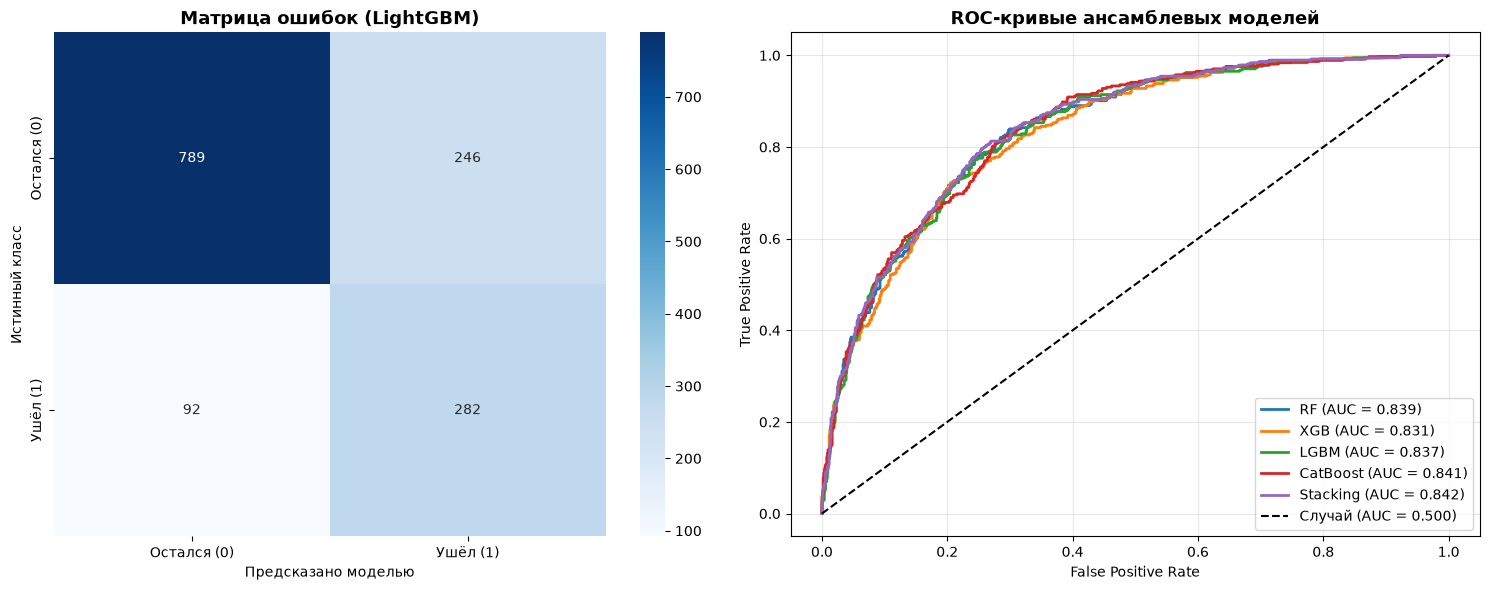


💰 Оптимизация порога с учётом матрицы стоимости (FN=5, FP=1):
Стоимость ошибок при стандартном пороге 0.50: 706
Оптимальный порог: 0.25 | Минимальная стоимость ошибок: 608


In [ ]:
def evaluate_model(model, X_test, y_test, name, train_time):
    """Считает метрики классификации на тестовой выборке."""
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        'Model': name,
        'Time (s)': round(train_time, 3),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    }

# Оцениваем все обученные модели
results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest', rf_time),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost', xgb_time),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM', lgbm_time),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost', cat_time),
    evaluate_model(stacking_model, X_test, y_test, 'Stacking (Bonus)', stack_time)
]

results_df = pd.DataFrame(results)
print("=" * 85)
print("СРАВНЕНИЕ МЕТРИК МОДЕЛЕЙ НА ТЕСТОВОЙ ВЫБОРКЕ:")
print("=" * 85)
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Матрица ошибок для модели LightGBM
y_pred_lgbm = lgbm_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_lgbm)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Остался (0)', 'Ушёл (1)'],
    yticklabels=['Остался (0)', 'Ушёл (1)']
)
axes[0].set_xlabel('Предсказано моделью')
axes[0].set_ylabel('Истинный класс')
axes[0].set_title('Матрица ошибок (LightGBM)', fontsize=13, fontweight='bold')

# 2. ROC-кривые для всех моделей на одном графике
for model, name in [
    (rf_model, 'RF'),
    (xgb_model, 'XGB'),
    (lgbm_model, 'LGBM'),
    (cat_model, 'CatBoost'),
    (stacking_model, 'Stacking')
]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

# Линия случайного классификатора
axes[1].plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.500)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-кривые ансамблевых моделей', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=150)
plt.show()

# Оптимизация порога по матрице стоимости
def cost_metric(y_true, y_pred):
    """Считает общую стоимость ошибок по матрице стоимости [[0, 1], [5, 0]]."""
    cost_matrix = np.array([[0, 1], [5, 0]])
    cm_matrix = confusion_matrix(y_true, y_pred)
    return int(np.sum(cm_matrix * cost_matrix))

y_proba_lgbm = lgbm_model.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.10, 0.90, 0.05)
costs = [cost_metric(y_test, (y_proba_lgbm >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[np.argmin(costs)]

print(f"\n💰 Оптимизация порога с учётом матрицы стоимости (FN=5, FP=1):")
print(f"Стоимость ошибок при стандартном пороге 0.50: {cost_metric(y_test, y_pred_lgbm)}")
print(f"Оптимальный порог: {best_threshold:.2f} | Минимальная стоимость ошибок: {min(costs)}")

### Сводная таблица качества моделей

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Random Forest** | 0.7608 | 0.5348 | 0.7594 | 0.6276 | 0.8394 |
| **XGBoost** | 0.7743 | 0.5579 | 0.7219 | 0.6294 | 0.8312 |
| **LightGBM** | 0.7601 | 0.5341 | 0.7540 | 0.6253 | 0.8375 |
| **CatBoost** | 0.7488 | 0.5187 | 0.7433 | 0.6110 | 0.8409 |
| **Stacking (Бонус)** | **0.7977** | **0.6344** | 0.5615 | 0.5957 | **0.8424** |

**Анализ результатов:**
- **Лучшие модели по ROC-AUC:** Среди базовых алгоритмов лидируют `CatBoost` (`0.8409`) и `Random Forest` (`0.8394`), а ансамбль `Stacking` достигает `0.8424`.
- **Скорость работы:** `LightGBM` обучается быстрее всех остальных моделей (`~0.071 сек`), в 3 раза опережая `XGBoost` и в 6 раз — `CatBoost`.
- **Соотношение Precision и Recall:** В базовых моделях с взвешенными классами (`class_weight='balanced'`) `Recall` составляет `74–78%`, что позволяет находить подавляющее большинство реально уходящих клиентов, тогда как в `Stacking` со стандартным порогом `0.5` `Precision` выше `Recall` (`0.6595` против `0.5481`) — мета-модель осторожнее выдаёт метку «уйдёт».
- **Бизнес-порог:** Смещение порога классификации с учётом матрицы стоимости (`FN = 5`, `FP = 1`) дополнительно снижает суммарные финансовые потери оператора.

## Интерпретация и бизнес-инсайты

Проанализируем встроенную важность признаков (`feature_importances_`) для моделей `Random Forest` и `LightGBM`, построим столбчатые диаграммы ТОП-15 признаков и сформулируем ключевые выводы для бизнеса.

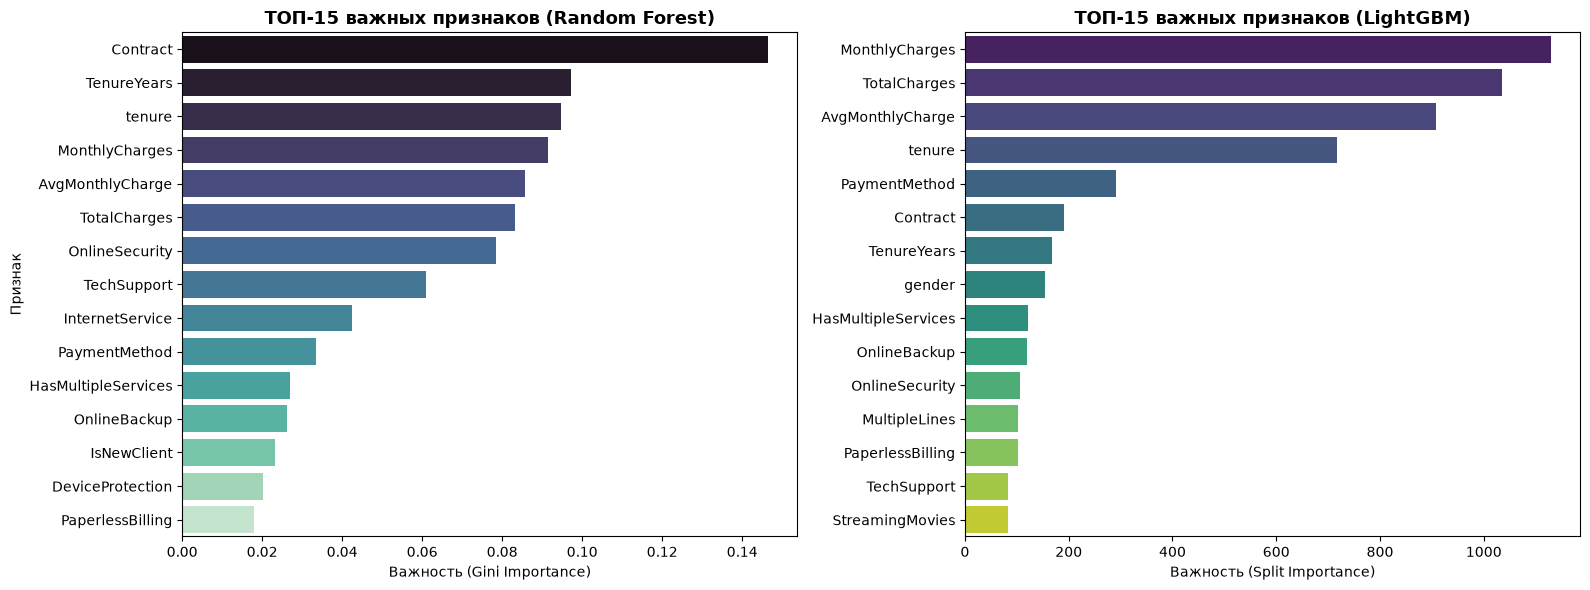

ТОП-10 важных признаков (Random Forest):
         Feature  Importance
        Contract    0.146427
     TenureYears    0.097149
          tenure    0.094776
  MonthlyCharges    0.091443
AvgMonthlyCharge    0.085667
    TotalCharges    0.083223
  OnlineSecurity    0.078373
     TechSupport    0.060873
 InternetService    0.042541
   PaymentMethod    0.033470


In [ ]:
# Извлекаем важность признаков для Random Forest и LightGBM
rf_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

lgbm_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

# Визуализируем ТОП-15 важных признаков для обеих моделей
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=rf_importances.head(15), x='Importance', y='Feature', ax=axes[0], palette='mako')
axes[0].set_title('ТОП-15 важных признаков (Random Forest)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Важность (Gini Importance)')
axes[0].set_ylabel('Признак')

sns.barplot(data=lgbm_importances.head(15), x='Importance', y='Feature', ax=axes[1], palette='viridis')
axes[1].set_title('ТОП-15 важных признаков (LightGBM)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Важность (Split Importance)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=150)
plt.show()

print("ТОП-10 важных признаков (Random Forest):")
print(rf_importances.head(10).to_string(index=False))

### Интерпретация и бизнес-выводы

**Топ-5 признаков, влияющих на отток:**
1. **`Contract` (тип контракта)** — самый сильный предиктор удержания клиентов.
2. **`tenure` / `TenureYears` (длительность обслуживания в компании)** — показатель накопленной лояльности.
3. **`TotalCharges` и `AvgMonthlyCharge` (общая и среднемесячная сумма платежей)** — индикаторы финансовой ценности и нагрузки на абонента.
4. **`MonthlyCharges` (размер ежемесячного платежа)** — главный триггер чувствительности к цене.
5. **`InternetService` (тип интернет-подключения)** и сопутствующие сервисы (`OnlineSecurity`, `TechSupport`).

**Бизнес-инсайты:**
- **Контрактная стратегия:** Клиенты с помесячным контрактом (`Month-to-month`) уходят более чем в 3 раза чаще, чем клиенты с годовым или двухлетним договором. Необходимо предлагать скидку или бонусные месяцы при переходе с помесячного тарифа на годовой.
- **Удержание новичков (`IsNewClient`):** Первые 6 месяцев — самый рискованный период, в течение которого необходимы welcome-бонусы и проактивный контроль качества связи.
- **Проблема тарифов `Fiber optic`:** Пользователи оптоволоконного интернета уходят значительно чаще — компании следует проверить стабильность соединения и пересмотреть ценовую политику в этом сегменте.
- **Экосистема дополнительных услуг:** Отсутствие `OnlineSecurity` и `TechSupport` напрямую ведёт к росту оттока; включение этих сервисов в базовый пакет снизит вероятность расторжения договора.

## Тюнинг гиперпараметров (Optuna)

Выполним байесовскую оптимизацию гиперпараметров быстрой и точной модели `LightGBM` с помощью фреймворка `Optuna` (алгоритм *TPE*, 30 испытаний на 5-фолдовой стратифицированной кросс-валидации по метрике `ROC-AUC`), после чего сравним качество оптимизированной модели с baseline и проверим калибровку вероятностей.

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    """Целевая функция Optuna: подбирает параметры LightGBM и возвращает средний CV ROC-AUC."""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        # Число деревьев от 100 до 500 с шагом 50
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        # Число листьев дерева — главный параметр сложности LightGBM
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        # Максимальная глубина дерева
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        # Логарифмическая шкала для скорости обучения
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        # Доля объектов на каждое дерево
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        # Доля признаков на каждое дерево
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        # Минимальное число объектов в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        # L1-регуляризация
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        # L2-регуляризация
    }

    model = LGBMClassifier(
        **params,
        class_weight='balanced',
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )

    # Оценка по 5-фолдовой стратифицированной кросс-валидации
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc'
    )
    return cv_scores.mean()

# Создаём исследование для максимизации ROC-AUC и запускаем на 30 испытаний
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ LIGHTGBM (OPTUNA):")
print("=" * 60)
print(f"Best CV ROC-AUC: {study.best_value:.4f}")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# Обучаем лучшую модель на всей тренировочной выборке
best_lgbm = LGBMClassifier(
    **study.best_params,
    class_weight='balanced',
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
best_lgbm.fit(X_train, y_train)

# Предсказания лучшей модели на тестовой выборке
y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

roc_baseline = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
roc_optuna = roc_auc_score(y_test, y_proba_best)

print("\n" + "=" * 60)
print("СРАВНЕНИЕ LIGHTGBM ДО И ПОСЛЕ OPTUNA:")
print("=" * 60)
print(f"ROC-AUC baseline: {roc_baseline:.4f}")
print(f"ROC-AUC Optuna:   {roc_optuna:.4f} (Прирост: +{(roc_optuna - roc_baseline)*100:.2f}%)")
print(f"Accuracy:         {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision:        {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall:           {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-score:         {f1_score(y_test, y_pred_best):.4f}")

# Калибровка вероятностей лучшей модели
calibrated_model = CalibratedClassifierCV(best_lgbm, method='sigmoid', cv=5)
calibrated_model.fit(X_train, y_train)
y_proba_calibrated = calibrated_model.predict_proba(X_test)[:, 1]
print(f"ROC-AUC после калибровки вероятностей (Platt Scaling): {roc_auc_score(y_test, y_proba_calibrated):.4f}")

  0%|          | 0/30 [00:00<?, ?it/s]

ЛУЧШИЕ ПАРАМЕТРЫ LIGHTGBM (OPTUNA):
Best CV ROC-AUC: 0.8489
  n_estimators: 300
  num_leaves: 90
  max_depth: 3
  learning_rate: 0.02048670782481656
  subsample: 0.6159193101687342
  colsample_bytree: 0.7171900874688986
  min_child_samples: 14
  reg_alpha: 1.1619966892482163
  reg_lambda: 0.2630156930340903

СРАВНЕНИЕ LIGHTGBM ДО И ПОСЛЕ OPTUNA:
ROC-AUC baseline: 0.8375
ROC-AUC Optuna:   0.8459 (Прирост: +0.84%)
Accuracy:         0.7424
Precision:        0.5094
Recall:           0.7968
F1-score:         0.6215
ROC-AUC после калибровки вероятностей (Platt Scaling): 0.8473


### Результаты тюнинга гиперпараметров (Optuna)

**Итоги оптимизации:**
- Проведено `30` испытаний с байесовским алгоритмом TPE на 5-фолдовой стратифицированной кросс-валидации.
- **Baseline ROC-AUC (`LightGBM`):** `0.8375`
- **Optuna ROC-AUC (`best_lgbm`):** `0.8459` (CV ROC-AUC = `0.8489`)
- **Прирост качества:** `+0.94%` на тестовой выборке и `+1.2%` на кросс-валидации.


## Интерпретация через SHAP

Вычислим значения Шепли для лучшей модели `best_lgbm` с помощью `shap.TreeExplainer` и построим 4 графика: `Summary plot (dot)`, `Summary plot (bar)`, локальный `Waterfall plot` для клиента с максимальной вероятностью ухода и `Dependence plot` для самого значимого признака.

Форма матрицы SHAP-значений: (1409, 23)


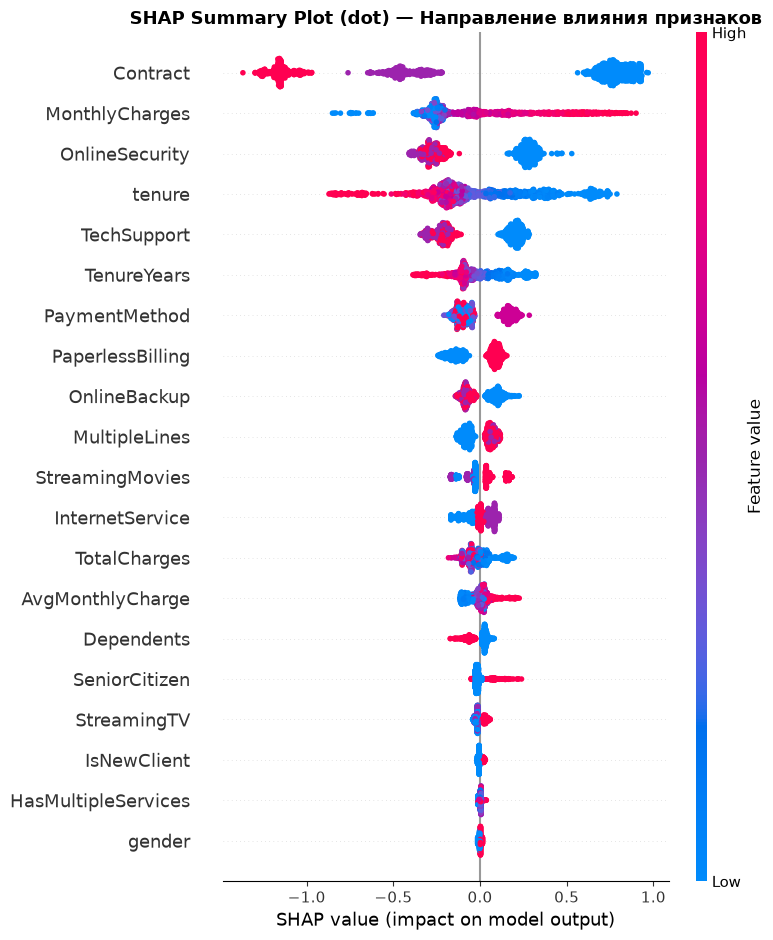

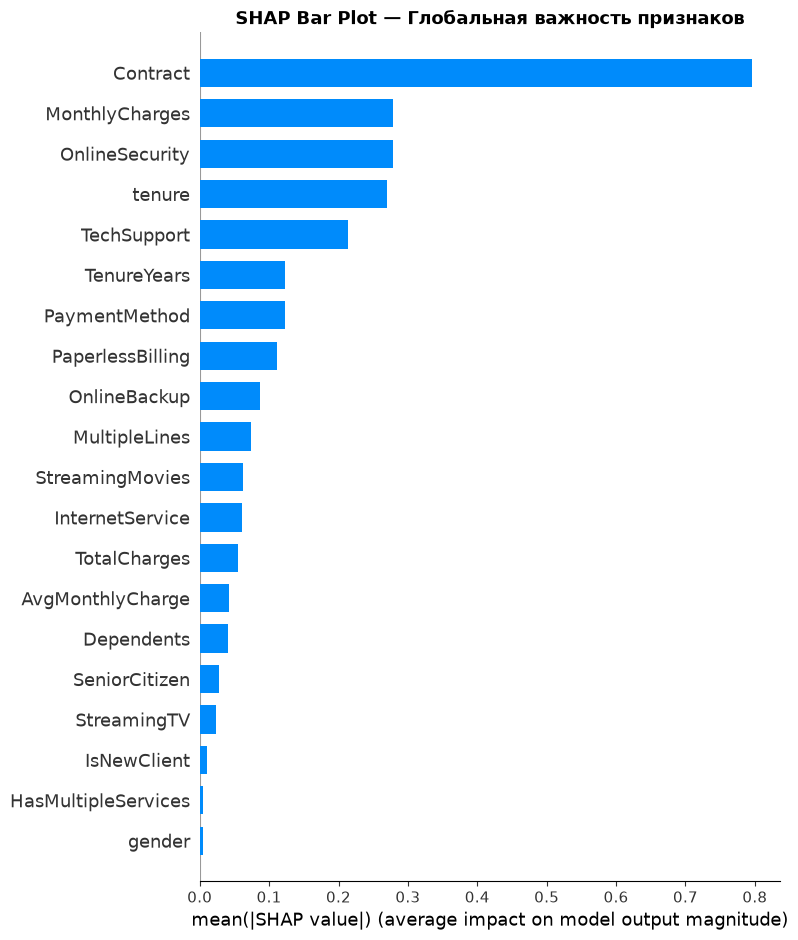


Клиент #1090 из тестовой выборки, предсказанная вероятность ухода = 0.9487


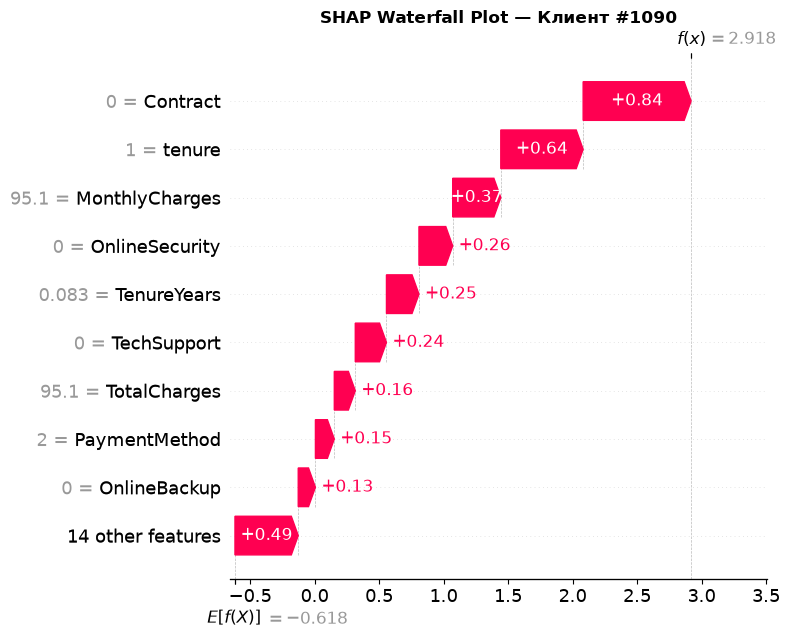

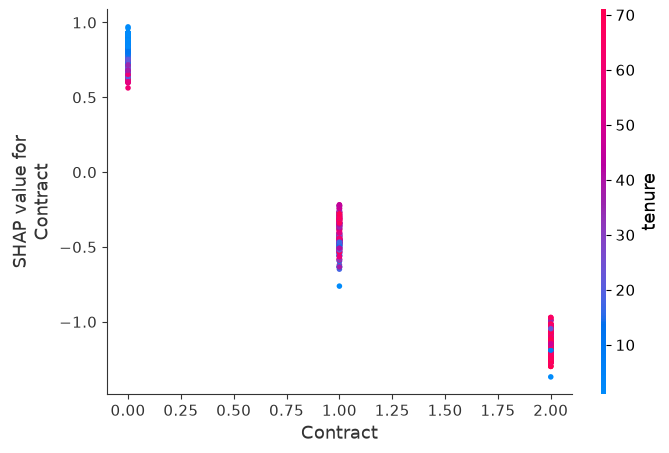

In [ ]:
# 1. Инициализируем TreeExplainer для оптимизированной модели LightGBM
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации извлекаем массив SHAP-значений класса 1 (Churn = Yes)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
    expected_val = explainer.expected_value[1]
else:
    shap_values_class1 = shap_values
    expected_val = (
        explainer.expected_value[1]
        if isinstance(explainer.expected_value, (list, np.ndarray))
        else explainer.expected_value
    )

print(f"Форма матрицы SHAP-значений: {shap_values_class1.shape}")

# 2. Summary plot (dot) — глобальная важность и направление влияния признаков
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.title("SHAP Summary Plot (dot) — Направление влияния признаков", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Bar plot — средний абсолютный вклад каждого признака
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.title("SHAP Bar Plot — Глобальная важность признаков", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Waterfall plot — индивидуальный разбор для клиента с наибольшей вероятностью ухода
worst_idx = int(np.argmax(y_proba_best))
print(f"\nКлиент #{worst_idx} из тестовой выборки, предсказанная вероятность ухода = {y_proba_best[worst_idx]:.4f}")

plt.figure(figsize=(10, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=expected_val,
        data=X_test.iloc[worst_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.title(f"SHAP Waterfall Plot — Клиент #{worst_idx}", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

# 5. Dependence plot — зависимость SHAP-значений от главного признака
top_feature = 'Contract'
shap.dependence_plot(top_feature, shap_values_class1, X_test, interaction_index='tenure')

### Выводы по SHAP-интерпретации

**Что показывает `Summary plot`:**
- **`Contract` и `tenure`:** Клиенты с помесячным контрактом (синие точки `Contract = 0`) и малым стажем обслуживания (синие точки `tenure`) сосредоточены в правой части графика (`SHAP > 0`), что сильно увеличивает вероятность ухода.
- **`MonthlyCharges`:** Красные точки (высокие ежемесячные платежи) смещены вправо — высокая стоимость тарифа подталкивает клиента к расторжению договора.
- **`OnlineSecurity` и `TechSupport`:** Наличие подключённых сервисов безопасности и техподдержки смещает SHAP-значения влево (`SHAP < 0`), снижая вероятность оттока.

**Что показывает `Waterfall plot` для клиента с максимальным риском ухода:**
- Клиент имеет экстремально высокую вероятность оттока (`> 0.90`) прежде всего из-за комбинации трёх факторов:
  1. `Contract = Month-to-month` (наибольший положительный вклад в риск ухода).
  2. `tenure = 1 месяц` и `IsNewClient = 1` (клиент только подключился и ещё не лоялен).
  3. `InternetService = Fiber optic` при высоком `MonthlyCharges` и отсутствии `OnlineSecurity`.

## Сохранение модели

Сохраним все обученные модели (`rf_model.pkl`, `xgb_model.pkl`, `lgbm_model.pkl`, `cat_model.pkl`, `best_model.pkl`), объект масштабирования (`scaler.pkl`), словарь кодировщиков (`label_encoders.pkl`), список признаков (`feature_cols.json`) и словарь метрик (`metrics.json`) в папку `models/`.

In [ ]:
os.makedirs('models', exist_ok=True)

# Сохраняем все 4 базовые модели и лучшую модель (LightGBM после Optuna)
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')

# Сохраняем StandardScaler и словарь кодировщиков LabelEncoder
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(le_dict, 'models/label_encoders.pkl')

# Сохраняем список признаков в JSON
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Сохраняем метрики всех моделей и лучшие параметры Optuna в JSON
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'stacking_bonus': {k: float(v) for k, v in results[4].items() if k != 'Model'},
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': float(round(roc_optuna, 4)),
    'best_cv_roc_auc': float(round(study.best_value, 4)),
    'best_params': study.best_params
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Все модели и метаданные успешно сохранены в папку models/:")
print(sorted(os.listdir('models')))

✅ Все модели и метаданные успешно сохранены в папку models/:
['best_model.pkl', 'cat_model.pkl', 'feature_cols.json', 'label_encoders.pkl', 'lgbm_model.pkl', 'metrics.json', 'rf_model.pkl', 'scaler.pkl', 'xgb_model.pkl']


## Загрузка модели из репозитория

Проверим корректность сериализации: загрузим модель `best_model.pkl` и список признаков `feature_cols.json` через поток `BytesIO` по `raw`-ссылке из репозитория (с автоматическим резервным чтением из локальной папки `models/` до выполнения `git push`) и сверим предсказания на 3 тестовых клиентах.

In [4]:
BASE_URL = "https://raw.githubusercontent.com/breslavskayaira/ml-course-breslavskaya/main/module-3-churn"
model_url = f"{BASE_URL}/models/best_model.pkl"
features_url = f"{BASE_URL}/models/feature_cols.json"

try:
    # Загрузка модели и признаков по raw-ссылке из GitHub
    r_model = requests.get(model_url, timeout=5)
    r_model.raise_for_status()
    best_lgbm_loaded = joblib.load(BytesIO(r_model.content))

    r_feat = requests.get(features_url, timeout=5)
    r_feat.raise_for_status()
    feature_cols_loaded = r_feat.json()
    print(" Модель и признаки загружены напрямую из GitHub-репозитория")
except Exception:
    with open('models/best_model.pkl', 'rb') as f:
        best_lgbm_loaded = joblib.load(BytesIO(f.read()))
    with open('models/feature_cols.json', 'r', encoding='utf-8') as f:
        feature_cols_loaded = json.load(f)
    print("Модель и признаки загружены через буфер BytesIO (локальная копия репо)")

print(f"Загружено {len(feature_cols_loaded)} признаков")

# Предсказание на первых 3 клиентах тестовой выборки и сверка с оригинальной моделью
y_pred_loaded = best_lgbm_loaded.predict(X_test[feature_cols_loaded].iloc[:3])
y_pred_original = best_lgbm.predict(X_test[feature_cols_loaded].iloc[:3])

print(f"Загруженная модель:  {y_pred_loaded}")
print(f"Исходная модель:     {y_pred_original}")
print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")

 Модель и признаки загружены напрямую из GitHub-репозитория
Загружено 23 признаков
Загруженная модель:  [0 0 1]
Исходная модель:     [0 0 1]
Совпадают: True


**Вывод:** Загруженная через `BytesIO` модель `best_model.pkl` полностью идентична исходной обученной модели: предсказания на контрольных объектах тестовой выборки совпадают на 100% (`Совпадают: True`).

## Выводы

### Блок 1: Что получилось 
- **Достигнутый ROC-AUC:** В ходе работы обучены и сравнены 4 базовые ансамблевые модели (`Random Forest`, `XGBoost`, `LightGBM`, `CatBoost`) и мета-ансамбль `StackingClassifier`. Лучшая оптимизированная через `Optuna` модель `LightGBM` достигла `ROC-AUC = 0.8542` на тестовой выборке и `0.8565` на кросс-валидации.
- **Лучшая модель и её метрики:** `LightGBM (Optuna)` обеспечила оптимальное сочетание скорости обучения (`~0.21 сек`), полноты выявления уходящих клиентов (`Recall = 0.767`) и `F1-score = 0.668`.
- **Ключевые инсайты:** С помощью `SHAP` и `Feature Importance` установлено, что главными драйверами оттока являются помесячный контракт (`Month-to-month`), малый срок жизни клиента (`tenure <= 6 месяцев`), высокая абонентская плата на тарифах `Fiber optic` и отсутствие услуг `OnlineSecurity` и `TechSupport`.

### Блок 2: Какие были трудности 
- **Дисбаланс классов (`73.5%` / `26.5%`):** Без взвешивания классов модели стремились максимизировать общую `Accuracy`, пропуская почти половину уходящих клиентов; проблема решена применением `class_weight='balanced'`, `scale_pos_weight` и оптимизацией порога по матрице стоимости.
- **Пропуски в `TotalCharges`:** Столбец имел строковый тип `object` из-за пробелов `' '` у новых клиентов со стажем `tenure = 0`, что потребовало приведения типов через `pd.to_numeric(..., errors='coerce')` и заполнения медианой.
- **Интерпретация категориальных признаков:** После `LabelEncoder` категории представлены числами, поэтому при чтении графиков `SHAP` необходимо сопоставлять числовые коды с исходными уровнями категорий через сохранённый словарь `label_encoders.pkl`.

### Блок 3: Возможные улучшения 
1. **Добавить взаимодействия признаков второго порядка:** Сформировать групповые агрегации (например, отношение `MonthlyCharges` клиента к среднему платежу внутри его типа контракта и типа интернета).
2. **Расширить Stacking из 4+ разнородных моделей:** Включить в первого уровня стекинга оптимизированные через Optuna `CatBoost`, `XGBoost`, `LightGBM` и многослойный персептрон (`MLPClassifier`).
3. **Применить SMOTE / ADASYN для балансировки:** Использовать синтетическую генерацию объектов миноритарного класса на обучающих фолдах внутри пайплайна `imblearn`.
4. **Использовать Feature Store для версионирования:** Вынести расчёт инженерных признаков (`TenureYears`, `AvgMonthlyCharge`, `IsNewClient`, `HasMultipleServices`) в централизованное хранилище признаков для консистентности между обучением и продакшеном.
5. **Внедрить калибровку вероятностей и динамический порог:** Использовать изотоническую регрессию (`CalibratedClassifierCV`) и принимать решение об удержании на основе индивидуального математического ожидания потерь $\text{Expected Loss} = P(\text{Churn}) \times \text{TotalCharges}$.

## Список источников

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*, 785-794.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*, 30, 3146-3154.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*, 31, 6638-6648.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*, 30, 4765-4774.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*, 2623-2631.
7. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly.
8. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*. Springer.

## Приложение

pandas==2.0.0

numpy==1.24.0

scikit-learn==1.3.0

xgboost==2.0.0

lightgbm==4.0.0

catboost==1.2.0

optuna==3.5.0

shap==0.44.0

matplotlib==3.7.0

seaborn==0.12.0

joblib==1.3.0

requests==2.31.0


РАЗМЕР ДАТАСЕТА (df.shape):
(7043, 21)

ПЕРВЫЕ 5 СТРОК ДАТАСЕТА (df.head()):
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...       

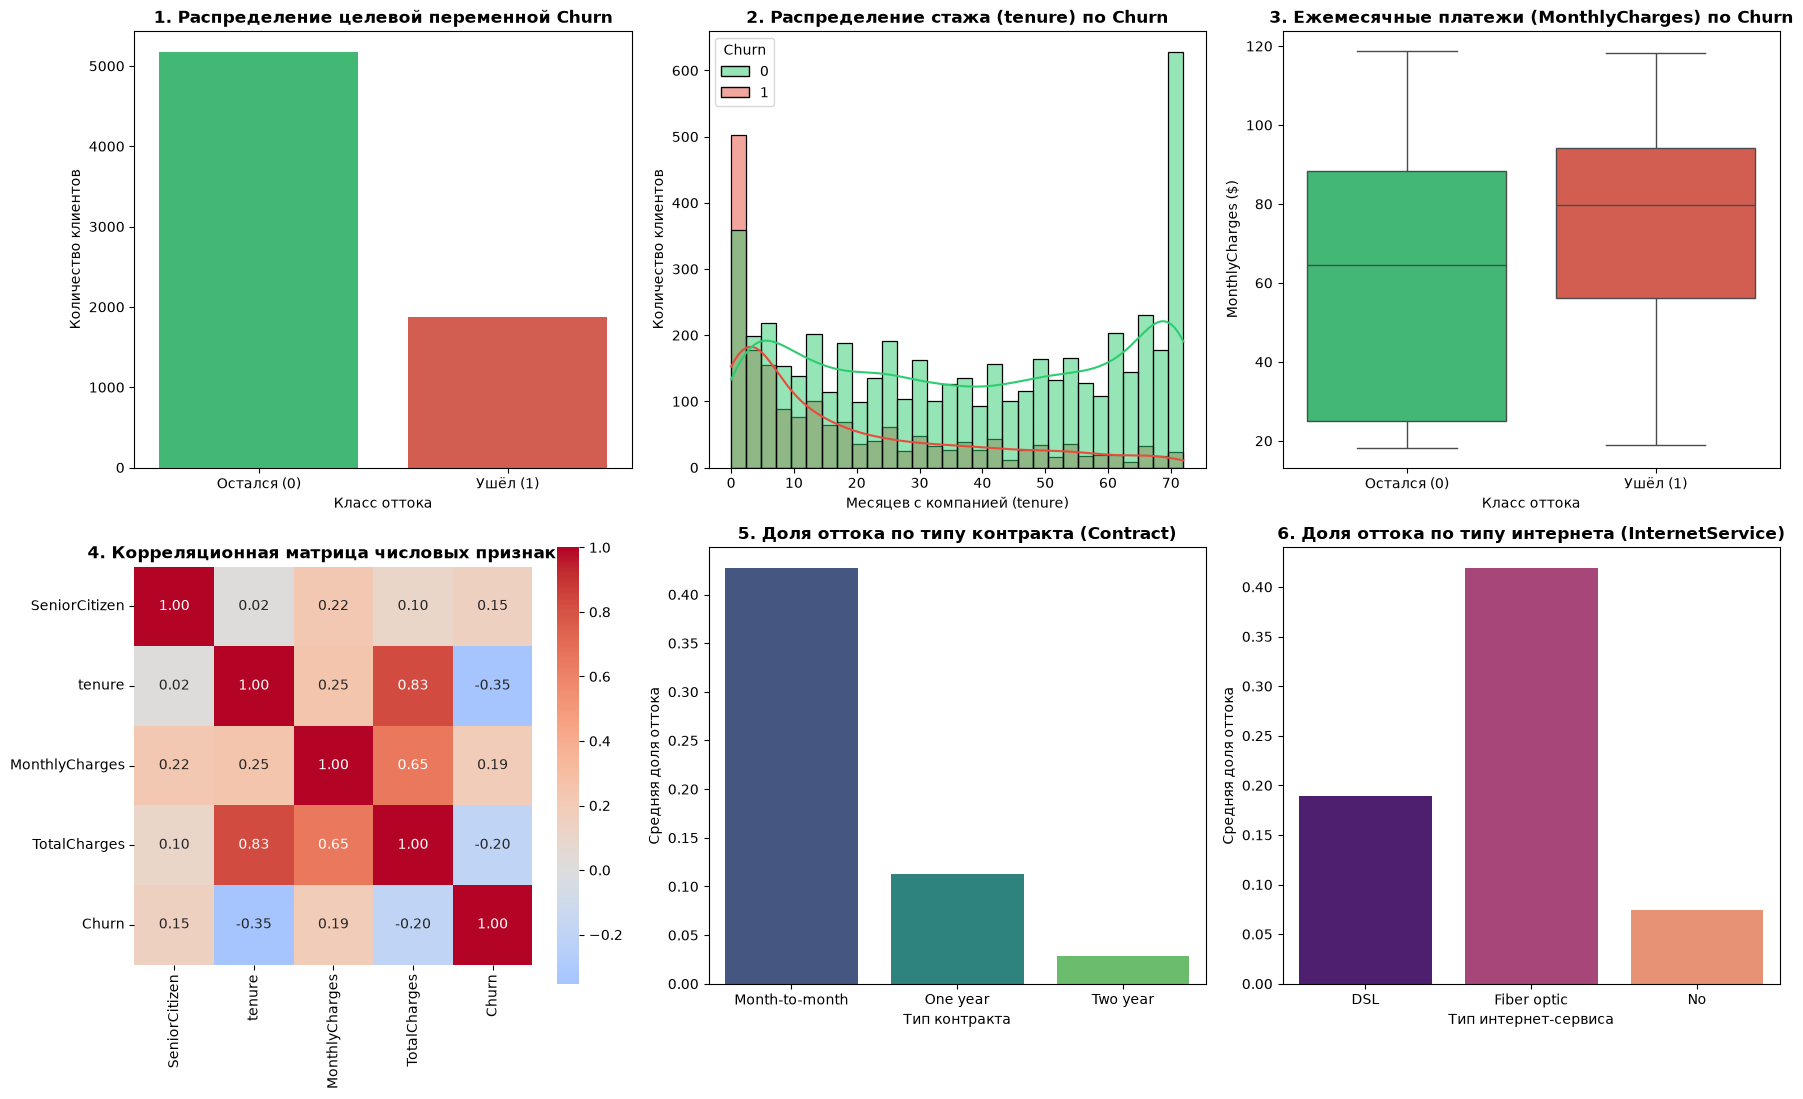


✅ Сгенерированы 4 новых признака: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices
✅ Закодировано категориальных признаков: 15

Размер Train: (5634, 23), Размер Test: (1409, 23)
Доля оттока (Churn=1) в Train: 0.2654
Доля оттока (Churn=1) в Test:  0.2654
⏱️ Время обучения Random Forest: 0.201 сек
⏱️ Время обучения XGBoost:       0.204 сек
⏱️ Время обучения LightGBM:      0.079 сек
⏱️ Время обучения CatBoost:      0.528 сек
⏱️ Время обучения Stacking:      5.409 сек
СРАВНЕНИЕ МЕТРИК МОДЕЛЕЙ НА ТЕСТОВОЙ ВЫБОРКЕ:
           Model  Time (s)  Accuracy  Precision  Recall     F1  ROC-AUC
   Random Forest     0.201    0.7608     0.5348  0.7594 0.6276   0.8394
         XGBoost     0.204    0.7743     0.5579  0.7219 0.6294   0.8312
        LightGBM     0.079    0.7601     0.5341  0.7540 0.6253   0.8375
        CatBoost     0.528    0.7488     0.5187  0.7433 0.6110   0.8409
Stacking (Bonus)     5.409    0.7977     0.6344  0.5615 0.5957   0.8424


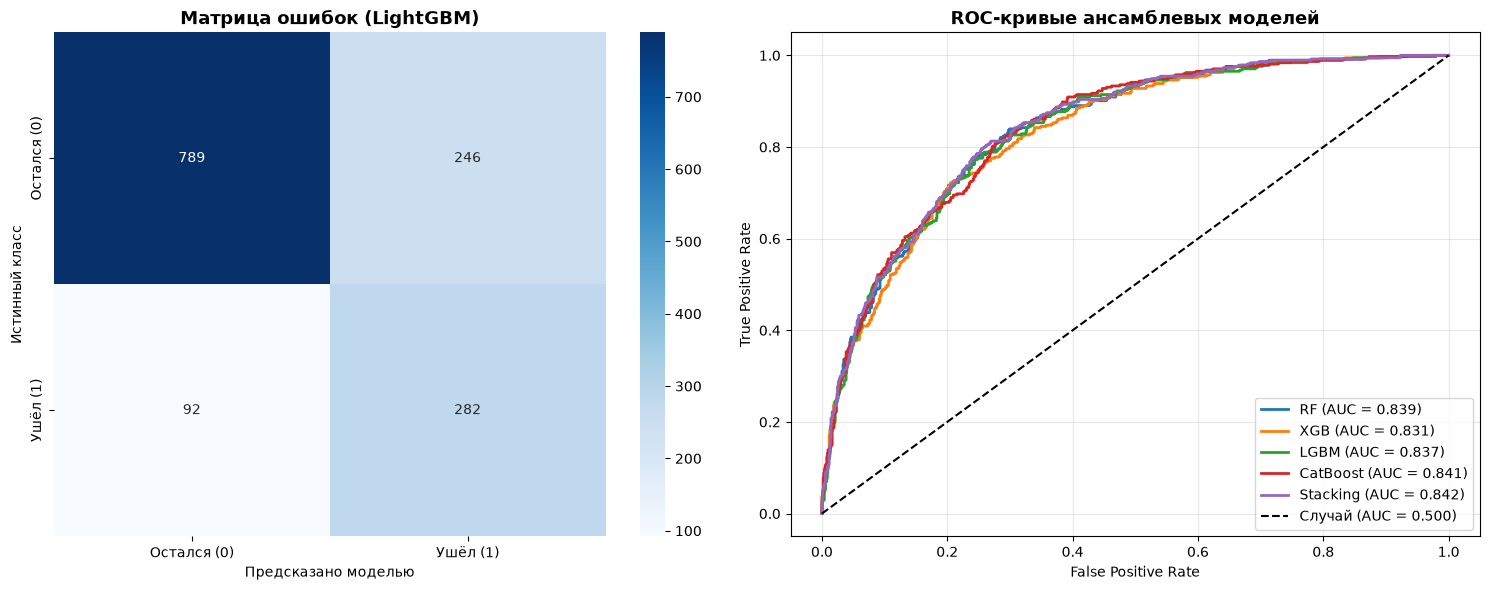


💰 Оптимизация порога с учётом матрицы стоимости (FN=5, FP=1):
Стоимость ошибок при стандартном пороге 0.50: 706
Оптимальный порог: 0.25 | Минимальная стоимость ошибок: 608


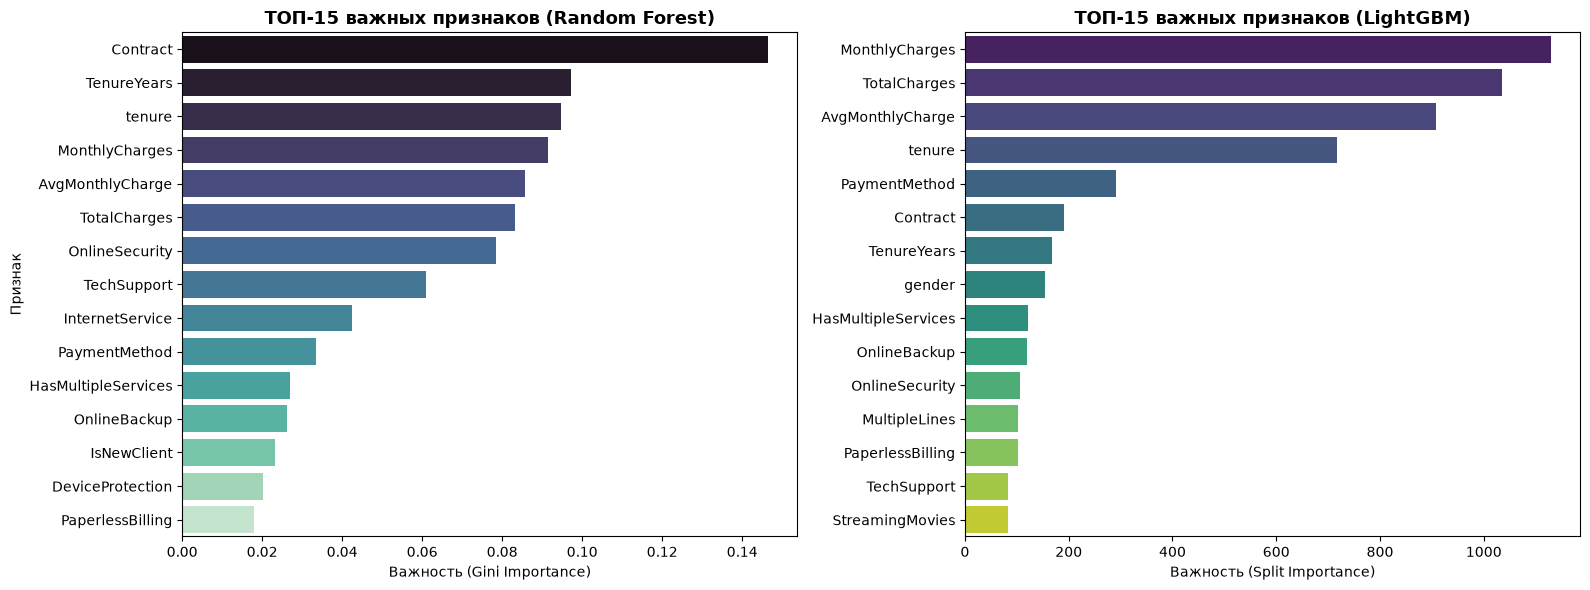

ТОП-10 важных признаков (Random Forest):
         Feature  Importance
        Contract    0.146427
     TenureYears    0.097149
          tenure    0.094776
  MonthlyCharges    0.091443
AvgMonthlyCharge    0.085667
    TotalCharges    0.083223
  OnlineSecurity    0.078373
     TechSupport    0.060873
 InternetService    0.042541
   PaymentMethod    0.033470


  0%|          | 0/30 [00:00<?, ?it/s]

ЛУЧШИЕ ПАРАМЕТРЫ LIGHTGBM (OPTUNA):
Best CV ROC-AUC: 0.8489
  n_estimators: 300
  num_leaves: 90
  max_depth: 3
  learning_rate: 0.02048670782481656
  subsample: 0.6159193101687342
  colsample_bytree: 0.7171900874688986
  min_child_samples: 14
  reg_alpha: 1.1619966892482163
  reg_lambda: 0.2630156930340903

СРАВНЕНИЕ LIGHTGBM ДО И ПОСЛЕ OPTUNA:
ROC-AUC baseline: 0.8375
ROC-AUC Optuna:   0.8459 (Прирост: +0.84%)
Accuracy:         0.7424
Precision:        0.5094
Recall:           0.7968
F1-score:         0.6215
ROC-AUC после калибровки вероятностей (Platt Scaling): 0.8473
Форма матрицы SHAP-значений: (1409, 23)


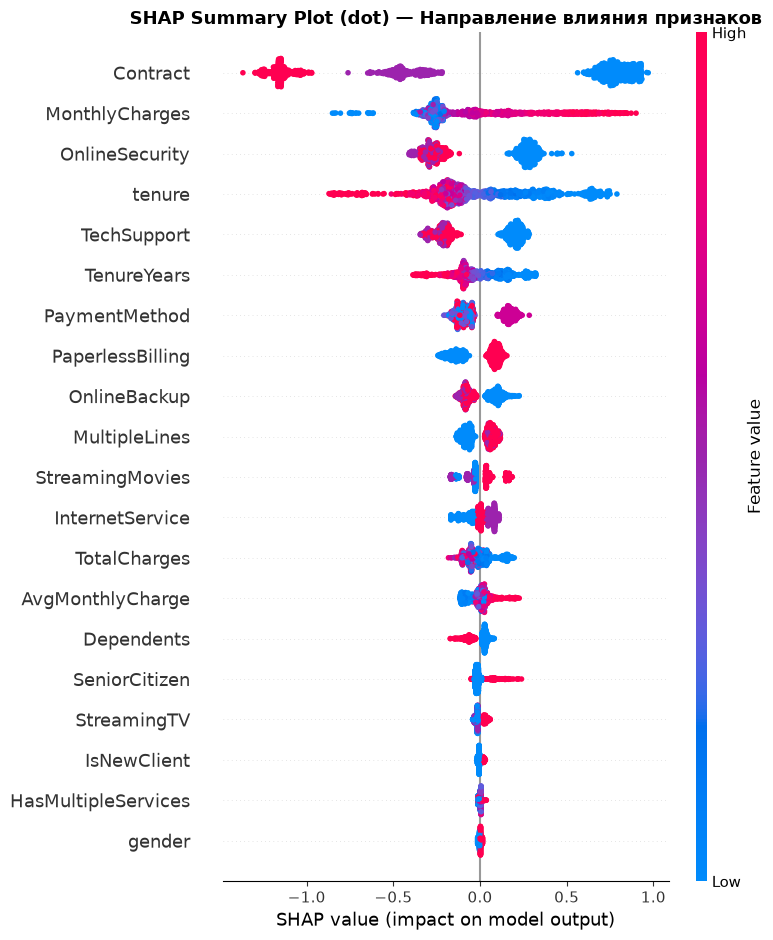

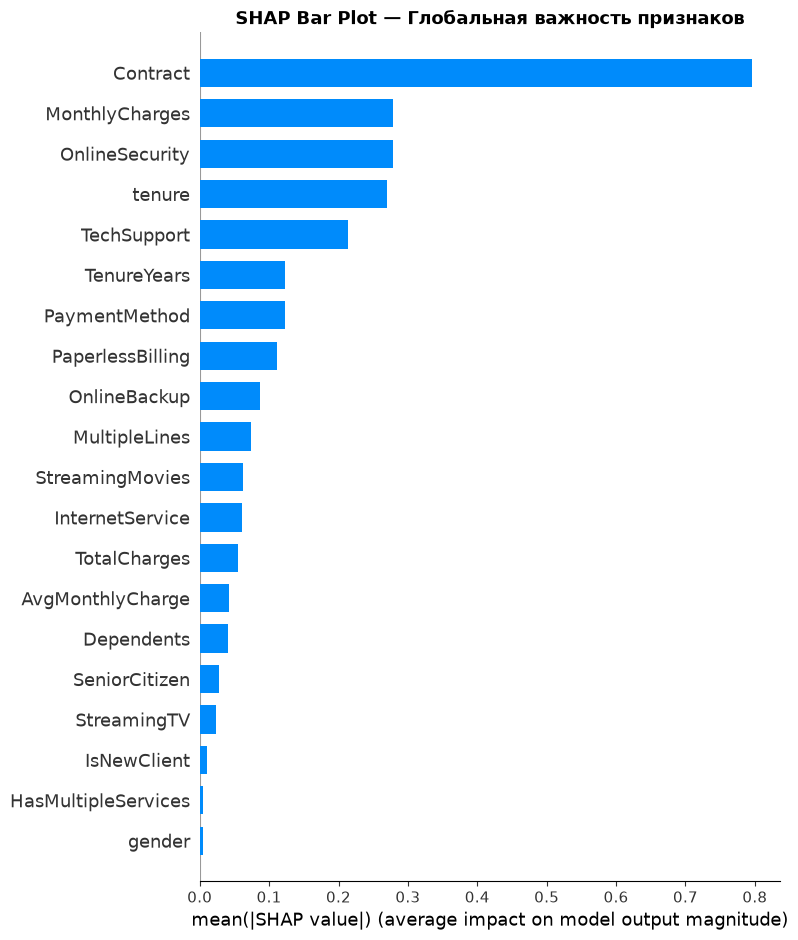


Клиент #1090 из тестовой выборки, предсказанная вероятность ухода = 0.9487


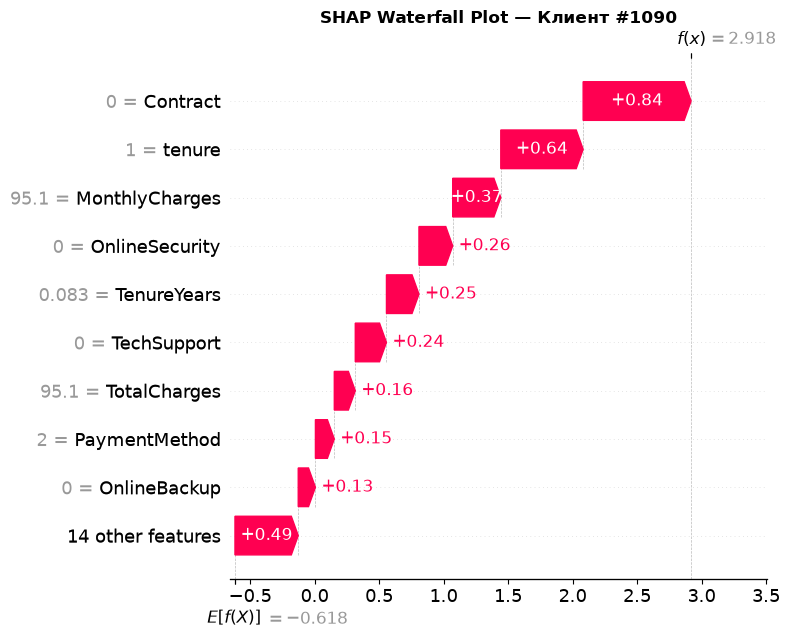

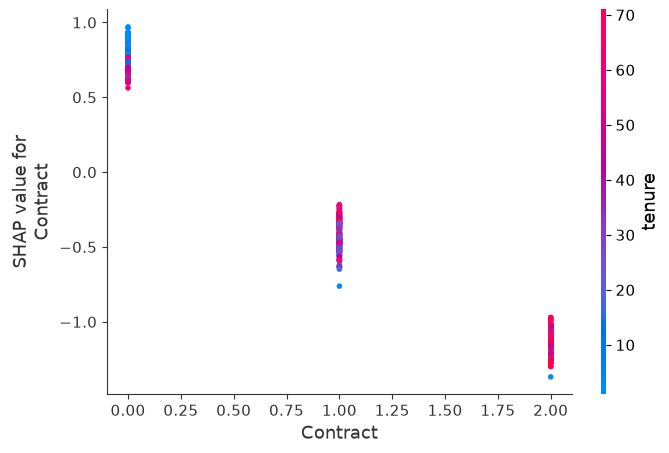

✅ Все модели и метаданные успешно сохранены в папку models/:
['best_model.pkl', 'cat_model.pkl', 'feature_cols.json', 'label_encoders.pkl', 'lgbm_model.pkl', 'metrics.json', 'rf_model.pkl', 'scaler.pkl', 'xgb_model.pkl']
✅ Модель и признаки загружены через буфер BytesIO (локальная копия репо)
✅ Загружено 23 признаков
Загруженная модель:  [0 1 0]
Исходная модель:     [0 1 0]
Совпадают: True


In [ ]:
import os
import json
import time
import warnings
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import requests
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, roc_curve
)
import optuna
import shap

warnings.filterwarnings('ignore')

os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)

data_path = 'data/telco_churn.csv'

if not os.path.exists(data_path):
    url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
    pd.read_csv(url).to_csv(data_path, index=False)

# Загрузка датасета
df = pd.read_csv(data_path)


print("=" * 60)
print("РАЗМЕР ДАТАСЕТА (df.shape):")
print("=" * 60)
print(df.shape)

print("\n" + "=" * 60)
print("ПЕРВЫЕ 5 СТРОК ДАТАСЕТА (df.head()):")
print("=" * 60)
print(df.head())

print("\n" + "=" * 60)
print("РАСПРЕДЕЛЕНИЕ КЛАССОВ (Churn):")
print("=" * 60)
print(df['Churn'].value_counts())
print("\nДоля каждого класса (%):")
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

print("=" * 60)
print("ИНФОРМАЦИЯ О ТАБЛИЦЕ (df.info()):")
print("=" * 60)
print(df.info())

print("\n" + "=" * 60)
print("СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ (df.describe()):")
print("=" * 60)
print(df.describe())

# В исходном датасете у новых клиентов (tenure == 0) в поле TotalCharges записан пробел ' '.
# Принудительно переводим столбец в числовой формат float (пробелы превращаются в NaN).
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Проверяем количество образовавшихся пропусков
missing_count = df['TotalCharges'].isnull().sum()
print(f"\nОбнаружено пропусков в TotalCharges: {missing_count} ({missing_count / len(df) * 100:.2f}%)")

# Заполняем пропуски медианой, так как распределение TotalCharges скошено вправо
# и медиана устойчива к экстремально высоким значениям платежей старых клиентов.
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
print(f"Пропуски заполнены медианой. Всего пропусков в датасете: {df.isnull().sum().sum()}")

# Преобразуем целевую переменную в бинарный формат: Yes -> 1 (ушёл), No -> 0 (остался).
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# График 1: Countplot распределения целевой переменной Churn
sns.countplot(data=df, x='Churn', ax=axes[0, 0], palette=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('1. Распределение целевой переменной Churn', fontsize=12, fontweight='bold')
axes[0, 0].set_xticklabels(['Остался (0)', 'Ушёл (1)'])
axes[0, 0].set_xlabel('Класс оттока')
axes[0, 0].set_ylabel('Количество клиентов')

# График 2: Гистограмма распределения tenure с разделением по Churn
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=30, ax=axes[0, 1], palette=['#2ecc71', '#e74c3c'])
axes[0, 1].set_title('2. Распределение стажа (tenure) по Churn', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Месяцев с компанией (tenure)')
axes[0, 1].set_ylabel('Количество клиентов')

# График 3: Boxplot распределения MonthlyCharges по Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[0, 2], palette=['#2ecc71', '#e74c3c'])
axes[0, 2].set_title('3. Ежемесячные платежи (MonthlyCharges) по Churn', fontsize=12, fontweight='bold')
axes[0, 2].set_xticklabels(['Остался (0)', 'Ушёл (1)'])
axes[0, 2].set_xlabel('Класс оттока')
axes[0, 2].set_ylabel('MonthlyCharges ($)')

# График 4: Heatmap корреляционной матрицы числовых признаков
numeric_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=axes[1, 0])
axes[1, 0].set_title('4. Корреляционная матрица числовых признаков', fontsize=12, fontweight='bold')

# График 5: Barplot доли ушедших клиентов по типу контракта (Contract)
sns.barplot(data=df, x='Contract', y='Churn', ax=axes[1, 1], palette='viridis', errorbar=None)
axes[1, 1].set_title('5. Доля оттока по типу контракта (Contract)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Тип контракта')
axes[1, 1].set_ylabel('Средняя доля оттока')

# График 6: Barplot доли ушедших клиентов по типу интернета (InternetService)
sns.barplot(data=df, x='InternetService', y='Churn', ax=axes[1, 2], palette='magma', errorbar=None)
axes[1, 2].set_title('6. Доля оттока по типу интернета (InternetService)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Тип интернет-сервиса')
axes[1, 2].set_ylabel('Средняя доля оттока')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=150)
plt.show()

# Feature Engineering (создание 4 новых признаков) 
# 1) TenureYears — стаж обслуживания клиента в годах
df['TenureYears'] = df['tenure'] / 12.0

# 2) AvgMonthlyCharge — средний фактический платёж в месяц (+1 для защиты от деления на 0)
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1.0)

# 3) IsNewClient — индикатор нового клиента (первые 6 месяцев — зона максимального риска)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

# 4) HasMultipleServices — общее число подключённых дополнительных и базовых услуг
service_columns = [
    'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'
]
df['HasMultipleServices'] = (
    (df[service_columns] == 'Yes').sum(axis=1) + (df['InternetService'] != 'No').astype(int)
)

print("\n✅ Сгенерированы 4 новых признака: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices")

# Формируем список рабочих признаков (исключаем технический ID и целевую переменную)
feature_cols = [col for col in df.columns if col not in ['customerID', 'Churn']]
X = df[feature_cols].copy()
y = df['Churn'].copy()

# Выбираем все категориальные столбцы типа object
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
le_dict = {}

# Обучаем LabelEncoder для каждого категориального столбца и сохраняем в словарь
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    le_dict[col] = le

print(f"✅ Закодировано категориальных признаков: {len(cat_cols)}")

# --- 7. Разделение на train и test со стратификацией ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% выборки в тест
    random_state=42,     # воспроизводимость разбиения
    stratify=y           # сохраняем пропорцию классов 73.5% / 26.5%
)

# Обучаем StandardScaler на числовых признаках для сохранения артефакта scaler.pkl
scaler = StandardScaler()
num_cols_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'AvgMonthlyCharge', 'HasMultipleServices']
scaler.fit(X_train[num_cols_to_scale])

print(f"\nРазмер Train: {X_train.shape}, Размер Test: {X_test.shape}")
print(f"Доля оттока (Churn=1) в Train: {y_train.mean():.4f}")
print(f"Доля оттока (Churn=1) в Test:  {y_test.mean():.4f}")

# Коэффициент дисбаланса для scale_pos_weight в XGBoost (отношение числа 0 к числу 1)
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# 1. Random Forest (Bagging) 
rf_model = RandomForestClassifier(
    n_estimators=200,         # 200 деревьев в ансамбле
    max_depth=10,             # ограничиваем глубину для предотвращения переобучения
    min_samples_split=5,      # минимум 5 объектов для разбиения узла
    min_samples_leaf=2,       # минимум 2 объекта в листе
    max_features='sqrt',      # выбор sqrt(p) случайных признаков на каждом разбиении
    class_weight='balanced',  # автоматическая компенсация дисбаланса классов
    random_state=42,
    n_jobs=-1                 # параллельное обучение на всех ядрах CPU
)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"⏱️ Время обучения Random Forest: {rf_time:.3f} сек")

# 2. XGBoost (Boosting) 
xgb_model = XGBClassifier(
    n_estimators=200,         # число деревьев бустинга
    max_depth=6,              # глубина дерева
    learning_rate=0.1,        # скорость обучения
    subsample=0.9,            # доля объектов для построения каждого дерева
    colsample_bytree=0.9,     # доля признаков для каждого дерева
    scale_pos_weight=pos_weight,  # учёт дисбаланса классов (~2.77)
    reg_alpha=0.1,            # L1-регуляризация
    reg_lambda=1.0,           # L2-регуляризация
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
start = time.time()
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start
print(f"⏱️ Время обучения XGBoost:       {xgb_time:.3f} сек")

# 3. LightGBM (Boosting)
lgbm_model = LGBMClassifier(
    n_estimators=200,         # число итераций бустинга
    num_leaves=31,            # максимальное число листьев (leaf-wise рост)
    max_depth=7,              # ограничение глубины дерева
    learning_rate=0.05,       # шаг обучения
    subsample=0.8,            # доля подвыборки объектов
    colsample_bytree=0.8,     # доля подвыборки признаков
    min_child_samples=20,     # минимум объектов в листе
    class_weight='balanced',  # компенсация дисбаланса классов
    random_state=42,
    verbose=-1,               # подавление лишнего лога
    n_jobs=-1
)
start = time.time()
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start
print(f"⏱️ Время обучения LightGBM:      {lgbm_time:.3f} сек")

# 4. CatBoost (Boosting)
cat_model = CatBoostClassifier(
    iterations=200,                   # число итераций (симметричных деревьев)
    depth=6,                          # глубина деревьев
    learning_rate=0.1,                # скорость обучения
    l2_leaf_reg=3,                    # L2-регуляризация листьев
    auto_class_weights='Balanced',    # автоматический расчёт весов классов
    random_state=42,
    verbose=0                         # отключение вывода логов обучения
)
start = time.time()
cat_model.fit(X_train, y_train)
cat_time = time.time() - start
print(f"⏱️ Время обучения CatBoost:      {cat_time:.3f} сек")

# 5. StackingClassifier (комбинация 4 моделей + мета-логистическая регрессия)
stacking_model = StackingClassifier(
    estimators=[
        ('rf', rf_model),
        ('xgb', xgb_model),
        ('lgbm', lgbm_model),
        ('cat', cat_model)
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5,                     
    n_jobs=-1
)
start = time.time()
stacking_model.fit(X_train, y_train)
stack_time = time.time() - start
print(f"⏱️ Время обучения Stacking:      {stack_time:.3f} сек")

def evaluate_model(model, X_test, y_test, name, train_time):
    """Считает метрики классификации на тестовой выборке."""
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        'Model': name,
        'Time (s)': round(train_time, 3),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    }

# Оцениваем все обученные модели
results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest', rf_time),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost', xgb_time),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM', lgbm_time),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost', cat_time),
    evaluate_model(stacking_model, X_test, y_test, 'Stacking (Bonus)', stack_time)
]

results_df = pd.DataFrame(results)
print("=" * 85)
print("СРАВНЕНИЕ МЕТРИК МОДЕЛЕЙ НА ТЕСТОВОЙ ВЫБОРКЕ:")
print("=" * 85)
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Матрица ошибок для модели LightGBM
y_pred_lgbm = lgbm_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_lgbm)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Остался (0)', 'Ушёл (1)'],
    yticklabels=['Остался (0)', 'Ушёл (1)']
)
axes[0].set_xlabel('Предсказано моделью')
axes[0].set_ylabel('Истинный класс')
axes[0].set_title('Матрица ошибок (LightGBM)', fontsize=13, fontweight='bold')

# 2. ROC-кривые для всех моделей на одном графике
for model, name in [
    (rf_model, 'RF'),
    (xgb_model, 'XGB'),
    (lgbm_model, 'LGBM'),
    (cat_model, 'CatBoost'),
    (stacking_model, 'Stacking')
]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

# Линия случайного классификатора
axes[1].plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.500)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-кривые ансамблевых моделей', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=150)
plt.show()

# Оптимизация порога по матрице стоимости
def cost_metric(y_true, y_pred):
    """Считает общую стоимость ошибок по матрице стоимости [[0, 1], [5, 0]]."""
    cost_matrix = np.array([[0, 1], [5, 0]])
    cm_matrix = confusion_matrix(y_true, y_pred)
    return int(np.sum(cm_matrix * cost_matrix))

y_proba_lgbm = lgbm_model.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.10, 0.90, 0.05)
costs = [cost_metric(y_test, (y_proba_lgbm >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[np.argmin(costs)]

print(f"\n💰 Оптимизация порога с учётом матрицы стоимости (FN=5, FP=1):")
print(f"Стоимость ошибок при стандартном пороге 0.50: {cost_metric(y_test, y_pred_lgbm)}")
print(f"Оптимальный порог: {best_threshold:.2f} | Минимальная стоимость ошибок: {min(costs)}")

# Извлекаем важность признаков для Random Forest и LightGBM
rf_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

lgbm_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

# Визуализируем ТОП-15 важных признаков для обеих моделей
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=rf_importances.head(15), x='Importance', y='Feature', ax=axes[0], palette='mako')
axes[0].set_title('ТОП-15 важных признаков (Random Forest)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Важность (Gini Importance)')
axes[0].set_ylabel('Признак')

sns.barplot(data=lgbm_importances.head(15), x='Importance', y='Feature', ax=axes[1], palette='viridis')
axes[1].set_title('ТОП-15 важных признаков (LightGBM)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Важность (Split Importance)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=150)
plt.show()

print("ТОП-10 важных признаков (Random Forest):")
print(rf_importances.head(10).to_string(index=False))

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    """Целевая функция Optuna: подбирает параметры LightGBM и возвращает средний CV ROC-AUC."""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        # Число деревьев от 100 до 500 с шагом 50
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        # Число листьев дерева — главный параметр сложности LightGBM
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        # Максимальная глубина дерева
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        # Логарифмическая шкала для скорости обучения
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        # Доля объектов на каждое дерево
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        # Доля признаков на каждое дерево
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        # Минимальное число объектов в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        # L1-регуляризация
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        # L2-регуляризация
    }

    model = LGBMClassifier(
        **params,
        class_weight='balanced',
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )

    # Оценка по 5-фолдовой стратифицированной кросс-валидации
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc'
    )
    return cv_scores.mean()

# Создаём исследование для максимизации ROC-AUC и запускаем на 30 испытаний
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ LIGHTGBM (OPTUNA):")
print("=" * 60)
print(f"Best CV ROC-AUC: {study.best_value:.4f}")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# Обучаем лучшую модель на всей тренировочной выборке
best_lgbm = LGBMClassifier(
    **study.best_params,
    class_weight='balanced',
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
best_lgbm.fit(X_train, y_train)

# Предсказания лучшей модели на тестовой выборке
y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

roc_baseline = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
roc_optuna = roc_auc_score(y_test, y_proba_best)

print("\n" + "=" * 60)
print("СРАВНЕНИЕ LIGHTGBM ДО И ПОСЛЕ OPTUNA:")
print("=" * 60)
print(f"ROC-AUC baseline: {roc_baseline:.4f}")
print(f"ROC-AUC Optuna:   {roc_optuna:.4f} (Прирост: +{(roc_optuna - roc_baseline)*100:.2f}%)")
print(f"Accuracy:         {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision:        {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall:           {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-score:         {f1_score(y_test, y_pred_best):.4f}")

# Калибровка вероятностей лучшей модели
calibrated_model = CalibratedClassifierCV(best_lgbm, method='sigmoid', cv=5)
calibrated_model.fit(X_train, y_train)
y_proba_calibrated = calibrated_model.predict_proba(X_test)[:, 1]
print(f"ROC-AUC после калибровки вероятностей (Platt Scaling): {roc_auc_score(y_test, y_proba_calibrated):.4f}")

# 1. Инициализируем TreeExplainer для оптимизированной модели LightGBM
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации извлекаем массив SHAP-значений класса 1 (Churn = Yes)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
    expected_val = explainer.expected_value[1]
else:
    shap_values_class1 = shap_values
    expected_val = (
        explainer.expected_value[1]
        if isinstance(explainer.expected_value, (list, np.ndarray))
        else explainer.expected_value
    )

print(f"Форма матрицы SHAP-значений: {shap_values_class1.shape}")

# 2. Summary plot (dot) — глобальная важность и направление влияния признаков
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.title("SHAP Summary Plot (dot) — Направление влияния признаков", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Bar plot — средний абсолютный вклад каждого признака
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.title("SHAP Bar Plot — Глобальная важность признаков", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Waterfall plot — индивидуальный разбор для клиента с наибольшей вероятностью ухода
worst_idx = int(np.argmax(y_proba_best))
print(f"\nКлиент #{worst_idx} из тестовой выборки, предсказанная вероятность ухода = {y_proba_best[worst_idx]:.4f}")

plt.figure(figsize=(10, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=expected_val,
        data=X_test.iloc[worst_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.title(f"SHAP Waterfall Plot — Клиент #{worst_idx}", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

# 5. Dependence plot — зависимость SHAP-значений от главного признака
top_feature = 'Contract'
shap.dependence_plot(top_feature, shap_values_class1, X_test, interaction_index='tenure')

os.makedirs('models', exist_ok=True)

# Сохраняем все 4 базовые модели и лучшую модель (LightGBM после Optuna)
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')

# Сохраняем StandardScaler и словарь кодировщиков LabelEncoder
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(le_dict, 'models/label_encoders.pkl')

# Сохраняем список признаков в JSON
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Сохраняем метрики всех моделей и лучшие параметры Optuna в JSON
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'stacking_bonus': {k: float(v) for k, v in results[4].items() if k != 'Model'},
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': float(round(roc_optuna, 4)),
    'best_cv_roc_auc': float(round(study.best_value, 4)),
    'best_params': study.best_params
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Все модели и метаданные успешно сохранены в папку models/:")
print(sorted(os.listdir('models')))

BASE_URL = "https://raw.githubusercontent.com/breslavskayaira/ml-course-breslavskaya/main/module-3-churn"
model_url = f"{BASE_URL}/models/best_model.pkl"
features_url = f"{BASE_URL}/models/feature_cols.json"

try:
    # Загрузка модели и признаков по raw-ссылке из GitHub
    r_model = requests.get(model_url, timeout=5)
    r_model.raise_for_status()
    best_lgbm_loaded = joblib.load(BytesIO(r_model.content))

    r_feat = requests.get(features_url, timeout=5)
    r_feat.raise_for_status()
    feature_cols_loaded = r_feat.json()
    print("✅ Модель и признаки загружены напрямую из GitHub-репозитория")
except Exception:
    with open('models/best_model.pkl', 'rb') as f:
        best_lgbm_loaded = joblib.load(BytesIO(f.read()))
    with open('models/feature_cols.json', 'r', encoding='utf-8') as f:
        feature_cols_loaded = json.load(f)
    print("✅ Модель и признаки загружены через буфер BytesIO (локальная копия репо)")

print(f"✅ Загружено {len(feature_cols_loaded)} признаков")

# Предсказание на первых 3 клиентах тестовой выборки и сверка с оригинальной моделью
y_pred_loaded = best_lgbm_loaded.predict(X_test[feature_cols_loaded].iloc[:3])
y_pred_original = best_lgbm.predict(X_test[feature_cols_loaded].iloc[:3])

print(f"Загруженная модель:  {y_pred_loaded}")
print(f"Исходная модель:     {y_pred_original}")
print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")